# DFT atom

In [1]:
using Pkg;
Pkg.activate("../.");

using SchrodingerEquationSolver
using SchrodingerEquationSolver: Grids, Potentials, MathUtils, Hydrogen, InitialConditions,
                                 OneDSchrodingerEquationSolver, OneDPoissonEquationSolver,
                                 EigenvalueFinders, BasisSets, Density, ExchangeCorrelation,
                                 PulayDensity
using Plots
using Libxc
using CSV

  Activating project at `~/Desktop/physics_coding_projects/julia/SchrodingerEquationSolver`
[ Info: Precompiling SchrodingerEquationSolver [4262c980-0eff-4bee-97c7-49b90bf0d56e] (cache misses: include_dependency fsize change (4), wrong dep version loaded (2), mismatched flags (12))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up


In [2]:
#Define parameters and produce an exponential grid.
r_max::Float64=50.0;#Max radius of space grid.
Z::Int64=6;#Atomic number, also used as the charge of coulomb potential.
potential_type="Free_atom"

"Free_atom"

In [3]:


#grid definition
grid_stru= Grids.ExponentialGrid(r_max, Z);
grid= grid_stru.grid;
dx_di= grid_stru.dx_di;
grid_i= grid_stru.grid_i;
N=grid_stru.N;
print("grid size ", N)

grid size 7835

In [4]:
x_func = Functional(:lda_x);
c_func = Functional(:lda_c_vwn);

In [5]:
V_colu::Vector{Float64}= Potentials.coulomb_potential(Z, grid_stru.grid);
#Initializing Hartree potential due to electron density. 
V_hartree::Vector{Float64}=zeros(Float64, N);
#Initializing exchange potential.
V_x::Vector{Float64}=zeros(Float64, N);
#Initializing correlation potential.
V_c::Vector{Float64}=zeros(Float64, N);
#Initializing energy exchange potential.
E_xp::Vector{Float64}=zeros(Float64, N);
#Initializing energy correlation potential.
E_cp::Vector{Float64}=zeros(Float64, N);
#Initializing exchange + correlation potential.
V_xcp::Vector{Float64}=zeros(Float64, N);
#Initializing the density.
density_in::Vector{Float64}= zeros(Float64, N);
m::Int64=15; #number of previous densities to store for Pulay mixing
alpha::Float64= 0.20; #mixing parameter for Pulay mixing
pulay_data= PulayDensity.init_pulay_data(N, m,alpha, grid_stru.dx_di, grid_stru.grid_i, grid_stru.grid_sqrt);
#Initializing total energy
E_total::Float64=1.0;
#Initializing total energy step before
E_total_before::Float64=2.0;
#Initializing energy from energy eigenvalues
E_eigen::Float64=0.0;
#Initializing exchange correlation potential value after integral
V_xc::Float64= 0.0;
#Initializing Hartree energy
E_hartree::Float64= 0.0;
#Initializing exchange energy
E_x::Float64= 0.0;
#Initializing correlation enrgy
E_c::Float64= 0.0;

E_kinetic::Float64= 0.0;

V_conf::Vector{Float64}= zeros(Float64, N);
#Initializing basis set data structure
basis= BasisSets.AtomBasisSet(Z, grid_stru.grid);

initial_condition_function_x_min = InitialConditions.atom_like_poly_at_r_min;
initial_condition_function_x_max = InitialConditions.exponential_decay_at_r_ref;

In [6]:
for i_orbi in basis.orbitals
    println(i_orbi.name)
    println(i_orbi.E)
end

1s
-18.0
2s
-4.5
2p
-4.5


In [7]:

#Energy minimization loop 
scl_total=1;
scl_pulay=1;
linear_mixing_loop=true;#the system starts with linear mixing
E_diff= abs(E_total - E_total_before);
while E_diff > 10.0e-11
    E_eigen=0.0;
    #Loop over every orbital to solve independent particle Schrodinger equation.
    for i_orbi in basis.orbitals
        #println(i_orbi.name)
        #angular potential for l orbital
        V_angu= Potentials.angular_potential(i_orbi.l, grid_stru.grid);
        #Assemble effective potential.
        V_effe= V_colu .+ V_angu .+ V_hartree .+ V_x .+ V_c.+ V_conf;
        V_effe_max= maximum(V_effe);
        V_effe_min= minimum(V_effe);
        #println(V_effe_max);
        #println(V_effe_min);
        energy_interval= EigenvalueFinders.guess_energy_interval(i_orbi.E, V_effe_max, V_effe_min);
        #println("energy_interval ", energy_interval);
        E_grid= Grids.UniformGrid(energy_interval[1], energy_interval[2], 300); #List with the energy grid points.

        E_intervals= EigenvalueFinders.find_eigenvalue_intervals(E_grid.grid, V_effe, grid_stru,
                    initial_condition_function_x_min,
                    initial_condition_function_x_max;
                    l=i_orbi.l, type= "single", debug=false);
        #println("E_intervals ",E_intervals);
        #print("here ")
        u_temp, ei_temp= EigenvalueFinders.illinois_eigenvalue_finder(E_intervals[1], V_effe, 
        grid_stru,initial_condition_function_x_min,
        initial_condition_function_x_max,i_orbi.l);
        #Update eigenvalue and eigenfunction in the basis set data structure.
        i_orbi.E=ei_temp;
        i_orbi.u=u_temp;
        E_eigen+= i_orbi.occu*ei_temp;
        #println(i_orbi.E)
        #println("--------------------------------")

    end
    #Update E_total_before from the E_total from the previous step.
    E_total_before= float(E_total);
    V_no_kinetic= V_colu .+ V_hartree .+ V_x .+ V_c;
    #Calculate density with new basis set.
    density_out= Density.calculate_density(basis);
    #Smooth the density with linear mixing (combination) of the previous and current densities.
    if E_diff > 10.0e-5 && linear_mixing_loop# scl_total < max_linear_mixing_steps
        #println("here1")
        density_in= Density.linear_mixing(density_in, density_out, alpha=alpha);
        #println("Linear mixing step: ", scl_total);
        #println("E_diff: ", E_diff);
    else
        #println("here2")
        linear_mixing_loop=false;#once in Pulay mixing, never go back to linear mixing
        density_in= PulayDensity.get_new_density_in(density_in, density_out, pulay_data, scl_pulay);
        scl_pulay+=1;
        #println("scl_total: ", scl_total);
        #println("Pulay mixing step: ", scl_pulay);
        #println("E_diff: ", E_diff);
        
    end

    #Solve Poisson equation to find the new Hartree potential.
    V_hartree= OneDPoissonEquationSolver.solver_uniform_integer_grid(Z, density_in, grid_stru);
    #Calculate new exchange and correlation potentials.
    V_xtemp, E_xp = evaluate(x_func, rho=density_in);
    V_x= vec(V_xtemp);
    V_ctemp, E_cp = evaluate(c_func, rho=density_in);
    V_c= vec(V_ctemp);
    #V_x, E_xp, V_c, E_cp= ExchangeCorrelation.potentials(density_in);
    #Add exchange and correlation potentials.
    V_xcp= V_x .+ V_c;
    #Integrals to calculate energy components.
    E_kinetic= E_eigen - 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, V_no_kinetic);
    #V_xc= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, V_xcp)

    E_hartree= 0.5*4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, V_hartree);

    E_x= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, E_xp);

    E_c= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, E_cp);
    E_colu= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, V_colu);
    #Calculate total energy.
    E_total= E_kinetic + E_hartree + E_x + E_c + E_colu;
    scl_total+=1;
    E_diff= abs(E_total - E_total_before);
    #println(E_total)
    #println("*****************************************")

end
println("Ekin ", E_kinetic)
println("Ecoul ", E_hartree)
println("Exc ", (E_x + E_c))
println("Etot ", E_total)
pred_energy_dict= Dict("Ekin"=> E_kinetic, "Exc"=>(E_x + E_c),
"Ecoul"=>E_hartree, "Etot"=>E_total);
for i_orbi in basis.orbitals
    merge!(pred_energy_dict, Dict(i_orbi.name => i_orbi.E));
    println("orbital ",i_orbi.name)
    println("eigenvalue ",i_orbi.E)
end
println("=========================================");
println("DFT calculation with Libxc for Z=$Z with $potential_type potential");
println("scl_total: ", scl_total);
println("scl_pulay: ", scl_pulay);


Ekin 37.19039091336292
Ecoul 17.627997752649875
Exc -4.72872436896973
Etot -37.42574853598938
orbital 1s
eigenvalue -9.947719860525773
orbital 2s
eigenvalue -0.5008670138837349
orbital 2p
eigenvalue -0.19918658004073228
DFT calculation with Libxc for Z=6 with Free_atom potential
scl_total: 32
scl_pulay: 8


In [7]:
#start dev

1s


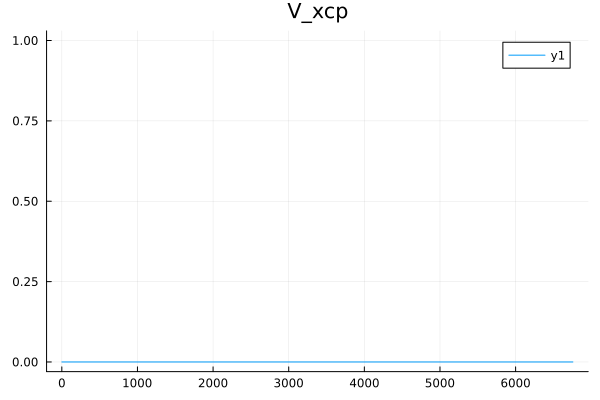

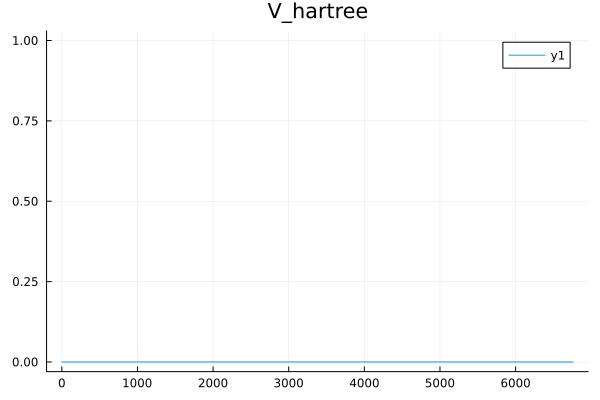

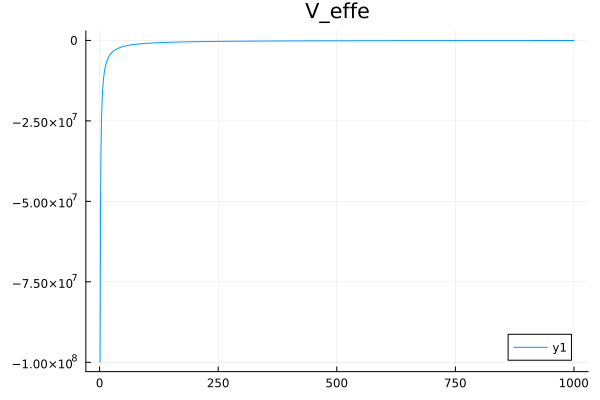

energy_interval (-0.575, -0.325)


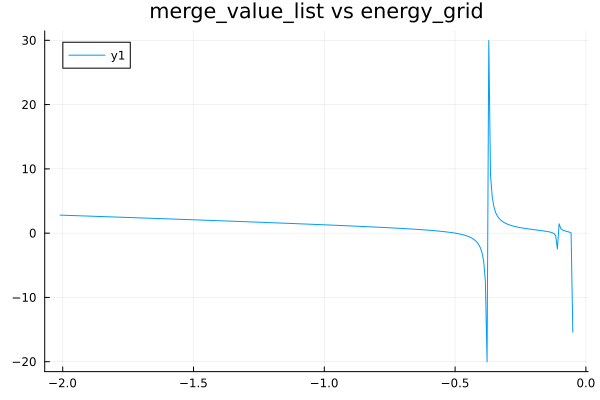

E_intervals [(-0.5088628762541807, -0.5023076923076923)]


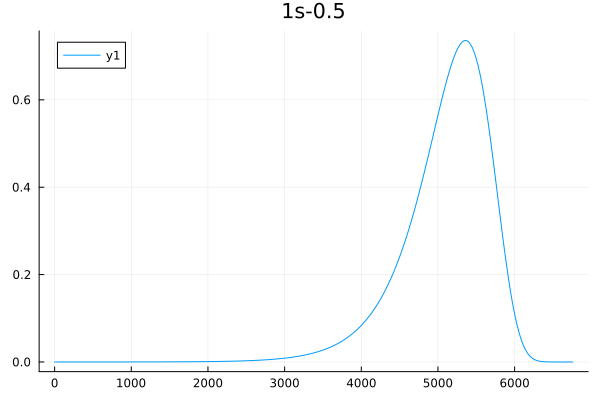

i_orbi.E -0.5000000000000563
--------------------------------
E_total -0.5026115723038105
*****************************************


In [8]:
#Energy minimization loop 

#Loop over every orbital to solve independent particle Schrodinger equation.
for i_orbi in basis.orbitals
    println(i_orbi.name)
    #angular potential for l orbital
    V_angu= Potentials.angular_potential(i_orbi.l, grid_stru.grid);
    #Assemble effective potential.
    V_effe= V_colu .+ V_angu .+ V_hartree .+ V_xcp;# .+ V_x .+ V_c;
    Plots.display(plot(grid_stru.grid_i, V_xcp, title= "V_xcp")) 
    Plots.display(plot(grid_stru.grid_i, V_hartree, title= "V_hartree")) 
    Plots.display(plot(grid_stru.grid_i[1:1000], V_effe[1:1000], title= "V_effe"))   
    V_effe_max= maximum(V_effe)
    V_effe_min= minimum(V_effe)
    energy_interval= EigenvalueFinders.guess_energy_interval(i_orbi.E, V_effe_max, V_effe_min);
    println("energy_interval ", energy_interval)
    #E_grid= Grids.UniformGrid(energy_interval[1], energy_interval[2], 300); 
    E_grid= Grids.UniformGrid(-2.01, -0.05, 300);
    #List with the energy grid points.

    E_intervals= EigenvalueFinders.find_eigenvalue_intervals(E_grid.grid, V_effe, grid_stru,
                initial_condition_function_x_min,
                initial_condition_function_x_max;
                l=i_orbi.l, debug=true);
    println("E_intervals ", E_intervals)
    u_temp, ei_temp= EigenvalueFinders.illinois_eigenvalue_finder(E_intervals[1], V_effe, 
    grid_stru,initial_condition_function_x_min,
    initial_condition_function_x_max,i_orbi.l);
    Plots.display(plot(grid_stru.grid_i, u_temp, title= string(i_orbi.name,i_orbi.E)))        
    #Update eigenvalue and eigenfunction in the basis set data structure.
    i_orbi.E=ei_temp;
    i_orbi.u=u_temp;
    E_eigen+= i_orbi.occu*ei_temp;
    println("i_orbi.E ",i_orbi.E)
    println("--------------------------------")

end
#Update E_total_before from the E_total from the previous step.
E_total_before= float(E_total);
#Calculate density with new basis set.
density_out= Density.calculate_density(basis);
#Smooth the density with linear mixing (combination) of the previous and current densities.
density_in= Density.linear_mixing(density_in, density_out, alpha=0.10);
#Solve Poisson equation to find the new Hartree potential.
V_hartree= OneDPoissonEquationSolver.solver_uniform_integer_grid(Z, density_in, grid_stru);
#Calculate new exchange and correlation potentials.
xc_all = evaluate(xc, rho=density_in);
#V_x, E_xp, V_c, E_cp= ExchangeCorrelation.potentials(density_in);
#Add exchange and correlation potentials.
V_xcp= vec(xc_all.vrho);#V_x .+ V_c;
E_xp= vec(xc_all.zk);
#Integrals to calculate energy components.

V_xc= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, V_xcp)

E_hartree= 0.5*4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, V_hartree);

E_x= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, E_xp);

#E_c= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, E_cp);

#Calculate total energy.
#E_total= E_eigen - E_hartree + E_x + E_c - V_xc;
E_total= E_eigen - E_hartree + E_x  - V_xc;
println("E_total ", E_total)
println("*****************************************")


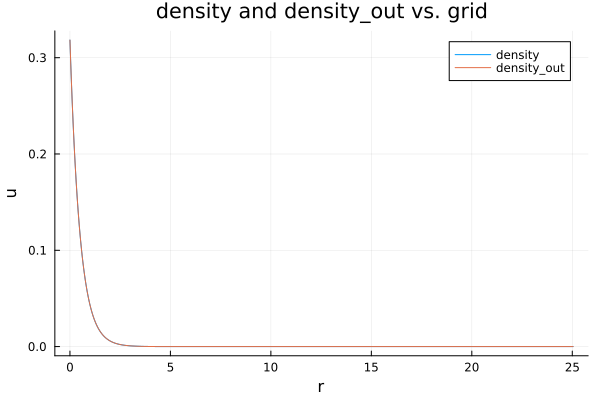

In [9]:
density= (1.0/(4.0*pi)).*((basis.orbitals[1].u).^2.0)./(grid.^2.0);
plot(
    grid,
    density,
    label="density",
    xlabel="r",
    ylabel="u",
    title="density and density_out vs. grid"
)
plot!(grid, density_out, label="density_out")

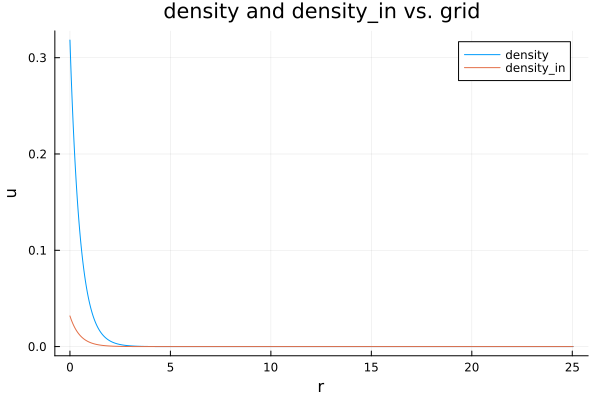

In [10]:
plot(
    grid,
    density,
    label="density",
    xlabel="r",
    ylabel="u",
    title="density and density_in vs. grid"
)
plot!(grid, density_in, label="density_in")

1s


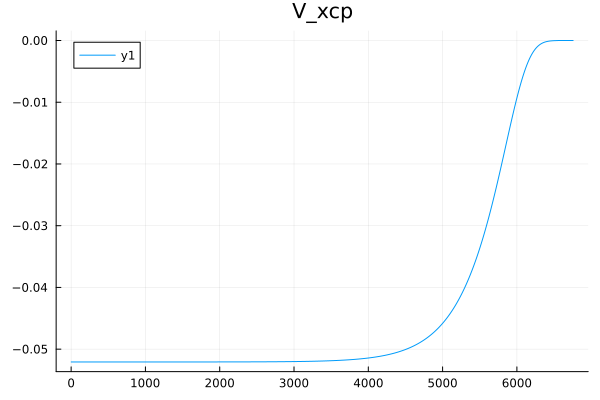

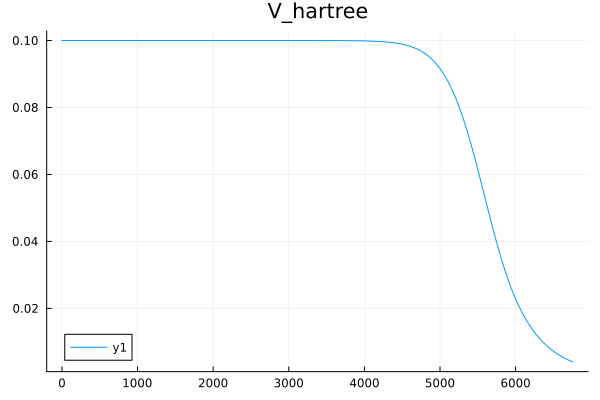

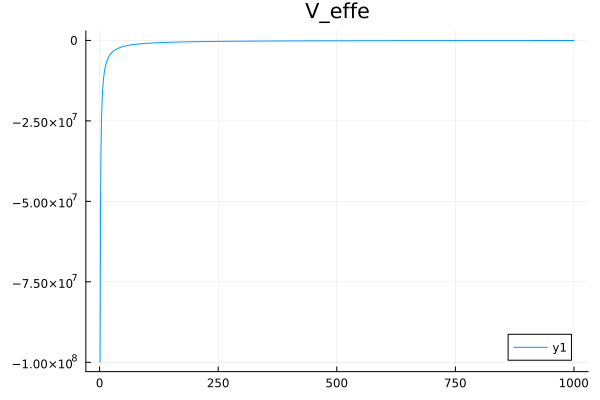

energy_interval (-0.5750000000000647, -0.3250000000000366)


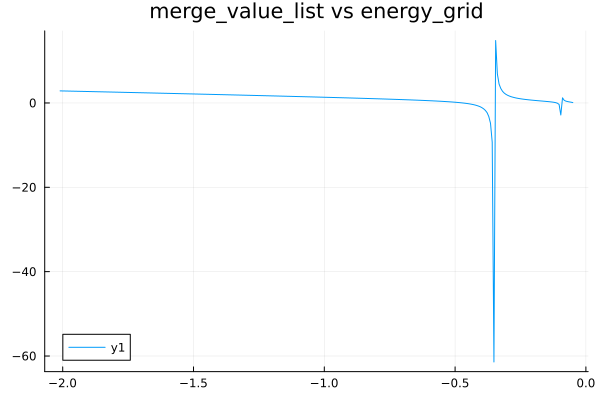

E_intervals [(-0.4826421404682275, -0.47608695652173916), (-0.12210702341137125, -0.11555183946488312)]


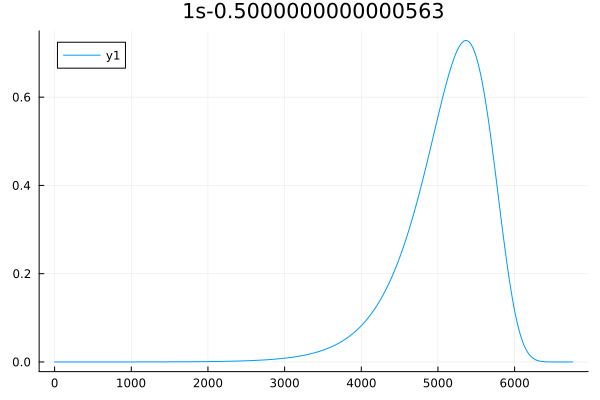

i_orbi.E -0.470838477142372
--------------------------------
E_total -0.9809700881508898
*****************************************


In [10]:
#Loop over every orbital to solve independent particle Schrodinger equation.
for i_orbi in basis.orbitals
    println(i_orbi.name)
    #angular potential for l orbital
    V_angu= Potentials.angular_potential(i_orbi.l, grid_stru.grid);
    #Assemble effective potential.
    V_effe= V_colu .+ V_angu .+ V_hartree .+ V_xcp;# .+ V_x .+ V_c;
    Plots.display(plot(grid_stru.grid_i, V_xcp, title= "V_xcp")) 
    Plots.display(plot(grid_stru.grid_i, V_hartree, title= "V_hartree")) 
    Plots.display(plot(grid_stru.grid_i[1:1000], V_effe[1:1000], title= "V_effe"))   
    V_effe_max= maximum(V_effe)
    V_effe_min= minimum(V_effe)
    energy_interval= EigenvalueFinders.guess_energy_interval(i_orbi.E, V_effe_max, V_effe_min);
    println("energy_interval ", energy_interval)
    #E_grid= Grids.UniformGrid(energy_interval[1], energy_interval[2], 300); 
    E_grid= Grids.UniformGrid(-2.01, -0.05, 300);
    #List with the energy grid points.

    E_intervals= EigenvalueFinders.find_eigenvalue_intervals(E_grid.grid, V_effe, grid_stru,
                initial_condition_function_x_min,
                initial_condition_function_x_max;
                l=i_orbi.l, debug=true);
    println("E_intervals ", E_intervals)
    u_temp, ei_temp= EigenvalueFinders.illinois_eigenvalue_finder(E_intervals[1], V_effe, 
    grid_stru,initial_condition_function_x_min,
    initial_condition_function_x_max,i_orbi.l);
    Plots.display(plot(grid_stru.grid_i, u_temp, title= string(i_orbi.name,i_orbi.E)))        
    #Update eigenvalue and eigenfunction in the basis set data structure.
    i_orbi.E=ei_temp;
    i_orbi.u=u_temp;
    E_eigen+= i_orbi.occu*ei_temp;
    println("i_orbi.E ",i_orbi.E)
    println("--------------------------------")

end
#Update E_total_before from the E_total from the previous step.
E_total_before= float(E_total);
#Calculate density with new basis set.
density_out= Density.calculate_density(basis);
#Smooth the density with linear mixing (combination) of the previous and current densities.
density_in= Density.linear_mixing(density_in, density_out, alpha=0.10);
#Solve Poisson equation to find the new Hartree potential.
V_hartree= OneDPoissonEquationSolver.solver_uniform_integer_grid(Z, density_in, grid_stru);
#Calculate new exchange and correlation potentials.
xc_all = evaluate(xc, rho=density_in);
#V_x, E_xp, V_c, E_cp= ExchangeCorrelation.potentials(density_in);
#Add exchange and correlation potentials.
V_xcp= vec(xc_all.vrho);#V_x .+ V_c;
E_xp= vec(xc_all.zk);
#Integrals to calculate energy components.

V_xc= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, V_xcp)

E_hartree= 0.5*4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, V_hartree);

E_x= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, E_xp);

#E_c= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, E_cp);

#Calculate total energy.
#E_total= E_eigen - E_hartree + E_x + E_c - V_xc;
E_total= E_eigen - E_hartree + E_x  - V_xc;
println("E_total ", E_total)
println("*****************************************")

In [ ]:
#end dev

1s


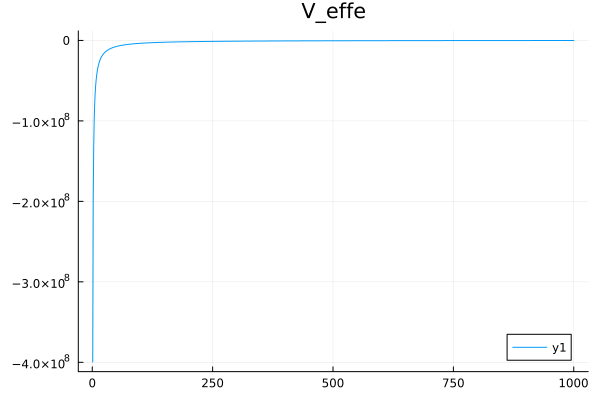

energy_interval (-2.3, -1.3)
E_intervals [(-2.005685618729097, -2.0023411371237456)]


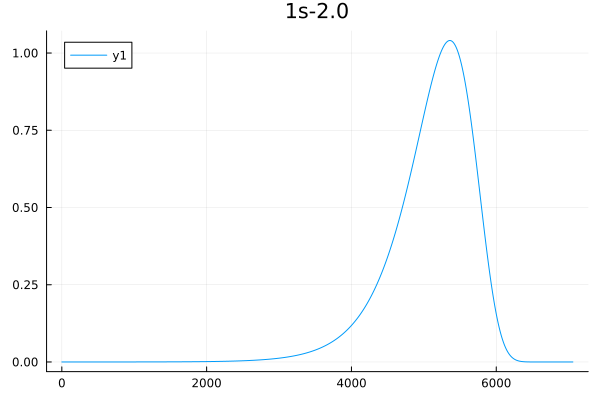

i_orbi.E -2.0000000000002323
--------------------------------
E_total -4.023663631718552
*****************************************
1s


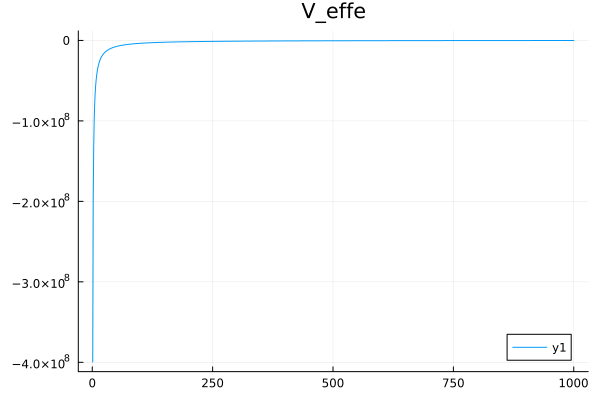

energy_interval (-2.300000000000267, -1.300000000000151)
E_intervals [(-1.808361204013588, -1.8050167224082365)]


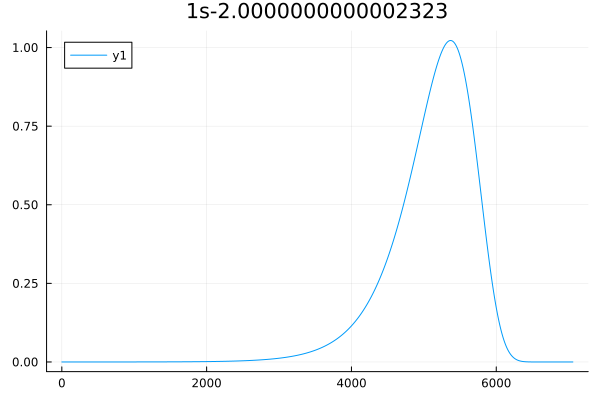

i_orbi.E -1.8027690537186565
--------------------------------
E_total -3.6916743373858427
*****************************************
1s


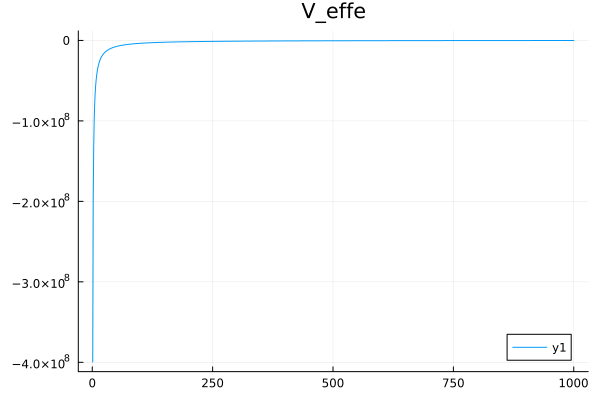

energy_interval (-2.073184411776455, -1.1717998849171267)
E_intervals [(-1.5968675046066427, -1.5938528406372137)]


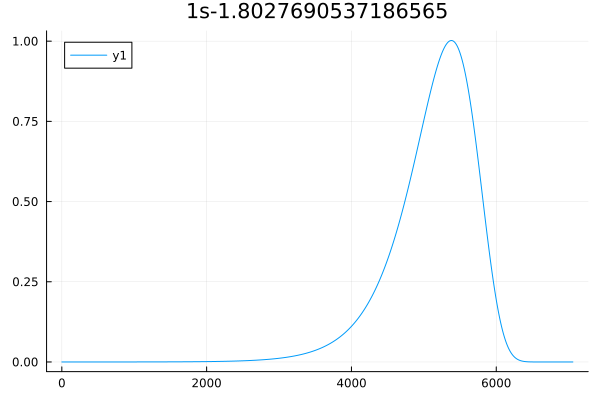

i_orbi.E -1.5915675541161793
--------------------------------
E_total -3.3565766755715676
*****************************************
1s


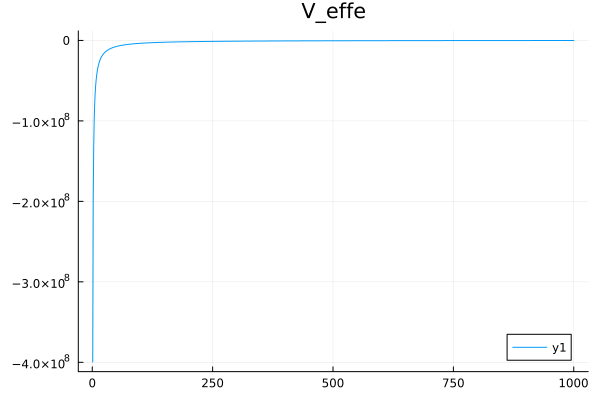

energy_interval (-1.8303026872336061, -1.0345189101755166)
E_intervals [(-1.412449667173004, -1.4097881829687964)]


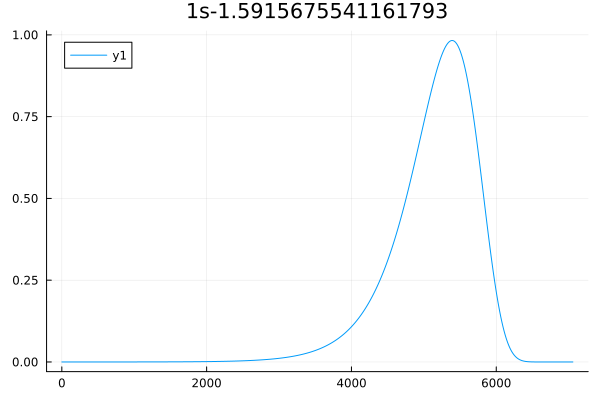

i_orbi.E -1.4074594257006416
--------------------------------
E_total -3.090032248110122
*****************************************
1s


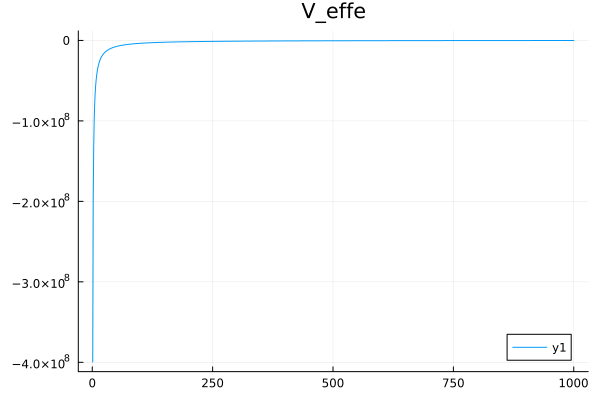

energy_interval (-1.6185783395557378, -0.9148486267054171)
E_intervals [(-1.2514150111120923, -1.2490614000323252)]


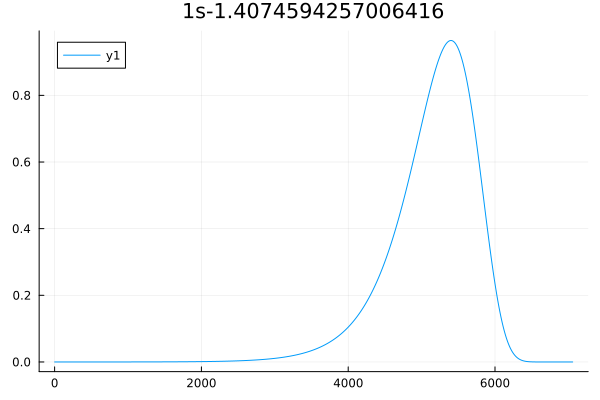

i_orbi.E -1.247854076825519
--------------------------------
E_total -2.879198087710895
*****************************************
1s


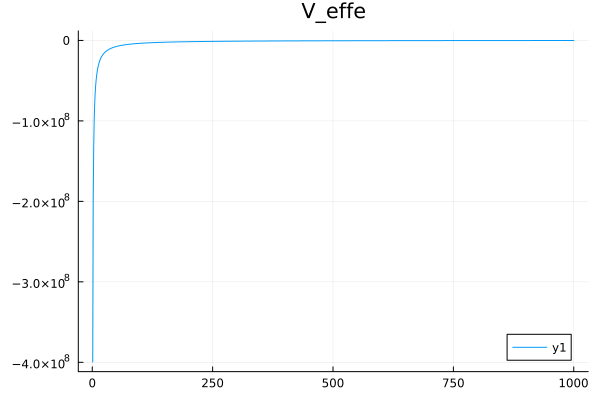

energy_interval (-1.4350321883493469, -0.8111051499365874)
E_intervals [(-1.11367846287923, -1.1115917503761772)]


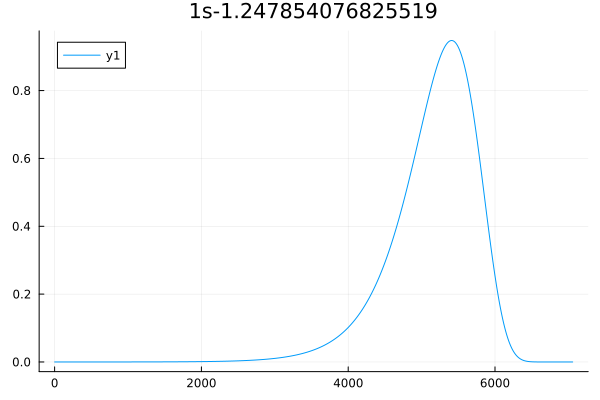

i_orbi.E -1.1098083902236364
--------------------------------
E_total -2.712707219216072
*****************************************
1s


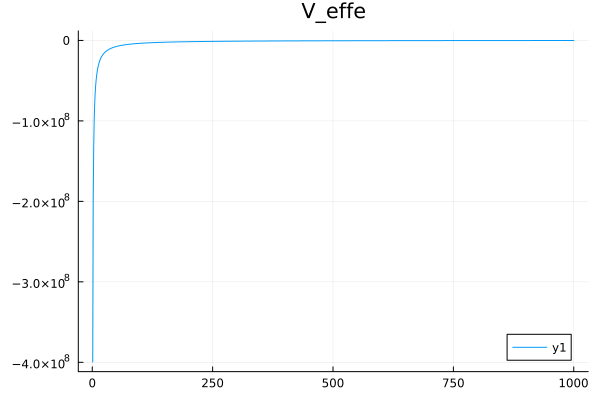

energy_interval (-1.276279648757182, -0.7213754536453637)
E_intervals [(-0.9941878840180636, -0.99233201714478)]


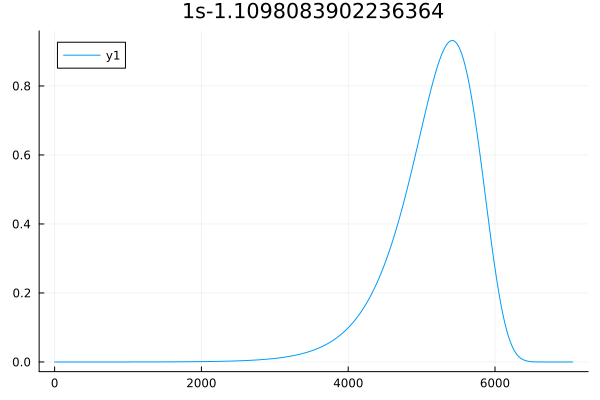

i_orbi.E -0.9905765760118367
--------------------------------
E_total -2.5812673022531305
*****************************************
1s


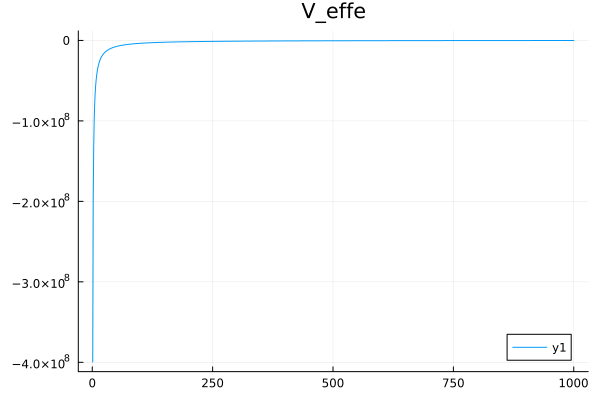

energy_interval (-1.1391630624136122, -0.6438747744076938)
E_intervals [(-0.8906906771263622, -0.8890341945577804)]


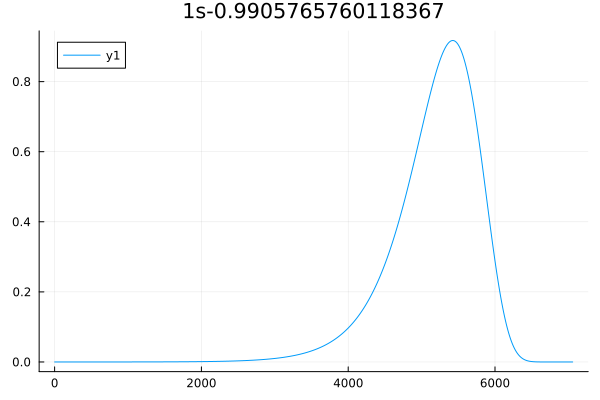

i_orbi.E -0.8876955446419416
--------------------------------
E_total -2.4774321259635217
*****************************************
1s


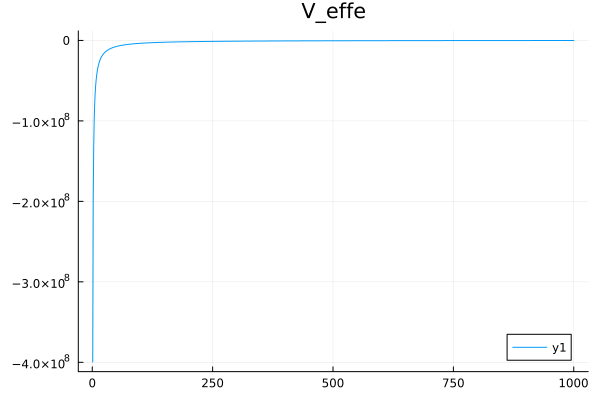

energy_interval (-1.0208498763382328, -0.577002104017262)
E_intervals [(-0.8011526512429028, -0.7996682105327992)]


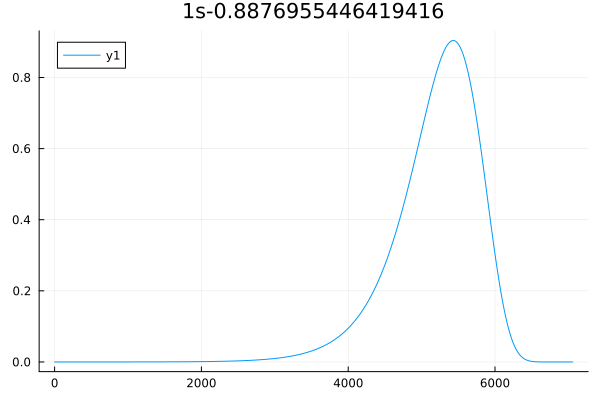

i_orbi.E -0.7989868257853533
--------------------------------
E_total -2.3952888194427535
*****************************************
1s


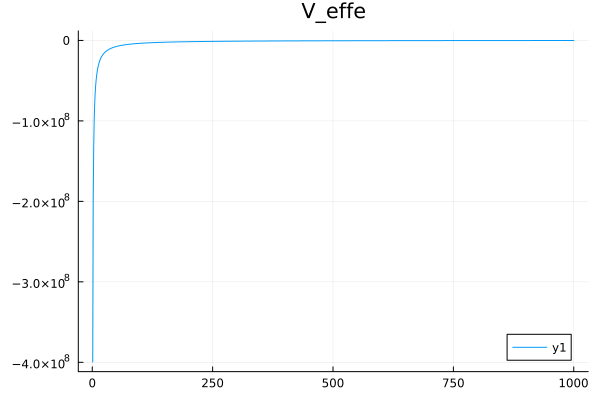

energy_interval (-0.9188348496531563, -0.5193414367604796)
E_intervals [(-0.7251005858757713, -0.7237644875048928)]


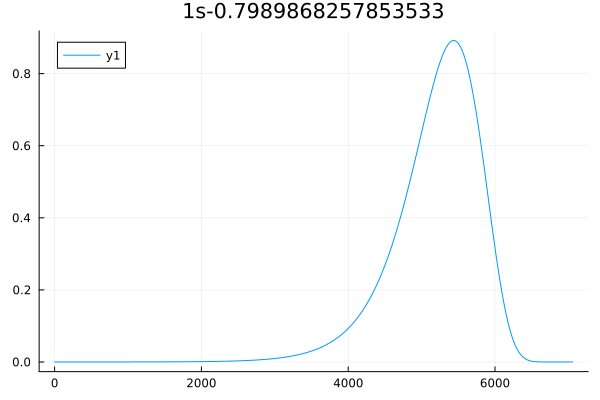

i_orbi.E -0.7225371881926647
--------------------------------
E_total -2.3301691690137494
*****************************************
1s


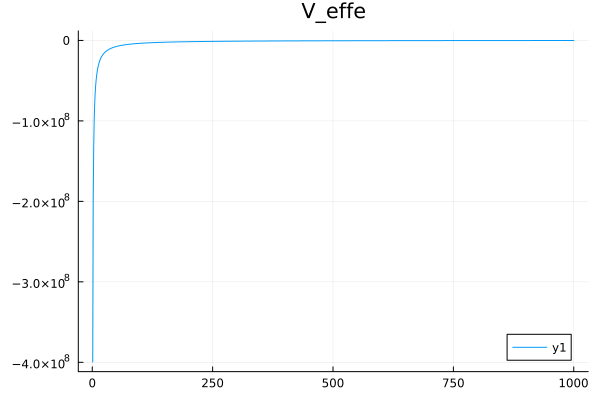

energy_interval (-0.8309177664215643, -0.46964917232523207)
E_intervals [(-0.6581371344624489, -0.6569288782949027)]


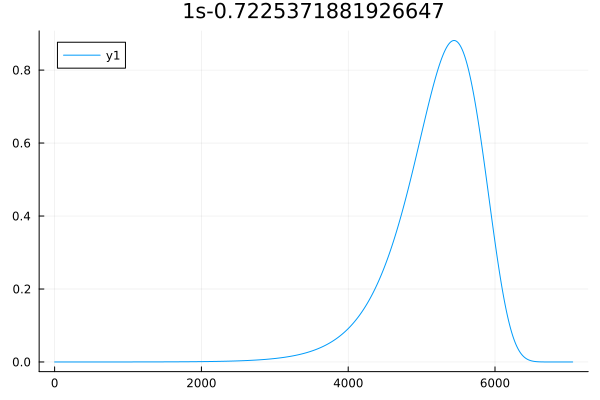

i_orbi.E -0.6566737202893504
--------------------------------
E_total -2.278403644259074
*****************************************
1s


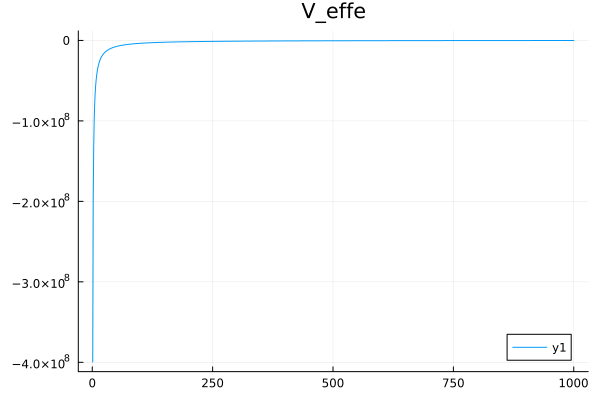

energy_interval (-0.755174778332753, -0.4268379181880778)
E_intervals [(-0.6014384558569854, -0.6003403392678728)]


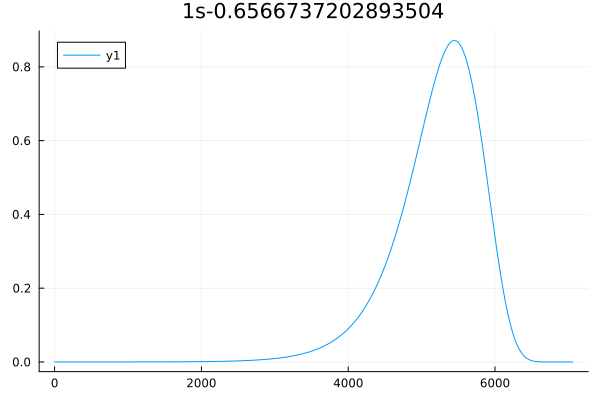

i_orbi.E -0.5999383782349635
--------------------------------
E_total -2.2371177222998715
*****************************************
1s


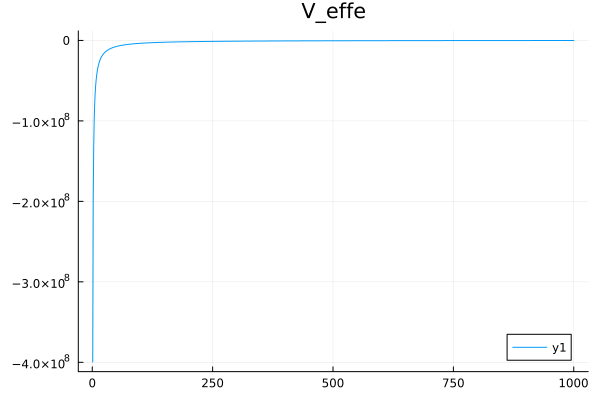

energy_interval (-0.689929134970208, -0.3899599458527263)
E_intervals [(-0.5524850583511612, -0.5514818169159856)]


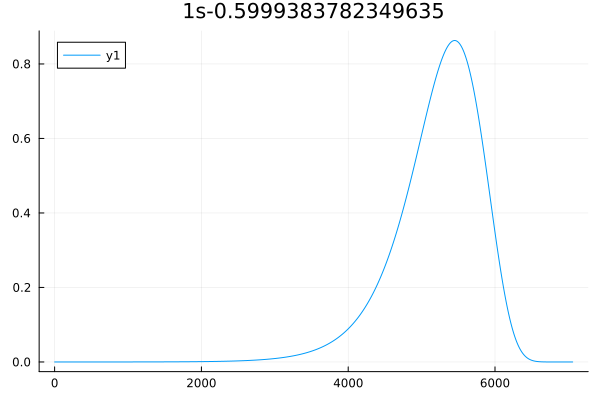

i_orbi.E -0.5510637810577939
--------------------------------
E_total -2.2040656556454103
*****************************************
1s


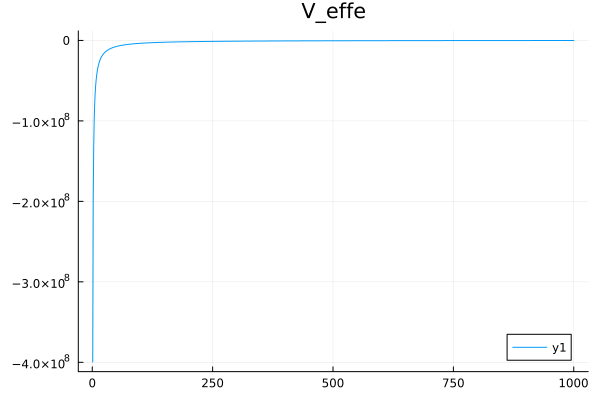

energy_interval (-0.6337233482164629, -0.358191457687566)
E_intervals [(-0.5102408287152181, -0.5093193173756566)]


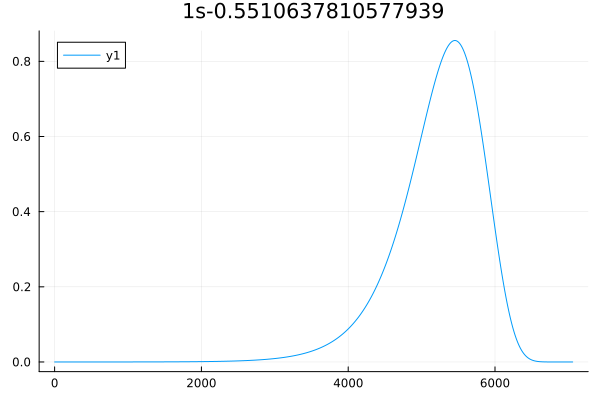

i_orbi.E -0.5089508856668095
--------------------------------
E_total -2.177496132324693
*****************************************
1s


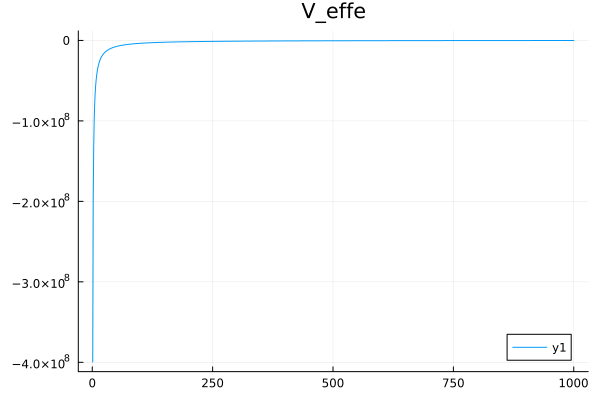

energy_interval (-0.5852935185168309, -0.33081807568342614)
E_intervals [(-0.4738009331951719, -0.47294984475760204)]


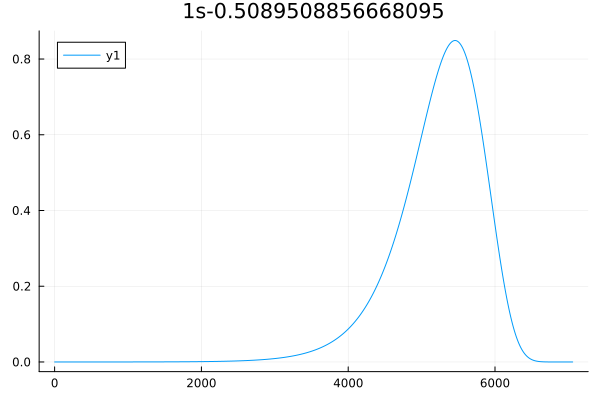

i_orbi.E -0.472648716419909
--------------------------------
E_total -2.1560446205473016
*****************************************
1s


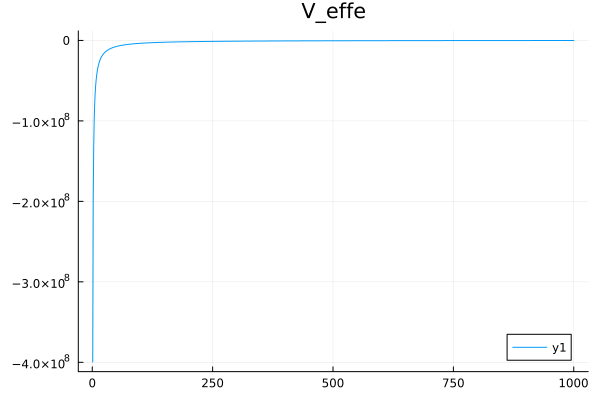

energy_interval (-0.5435460238828954, -0.30722166567294085)
E_intervals [(-0.4423770678599048, -0.44158668539097523)]


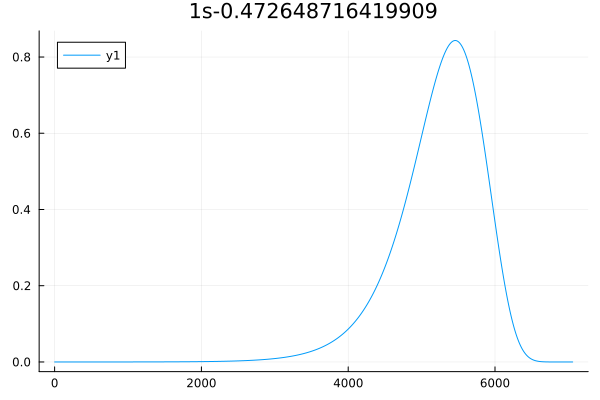

i_orbi.E -0.44133612666067923
--------------------------------
E_total -2.138647789681012
*****************************************
1s


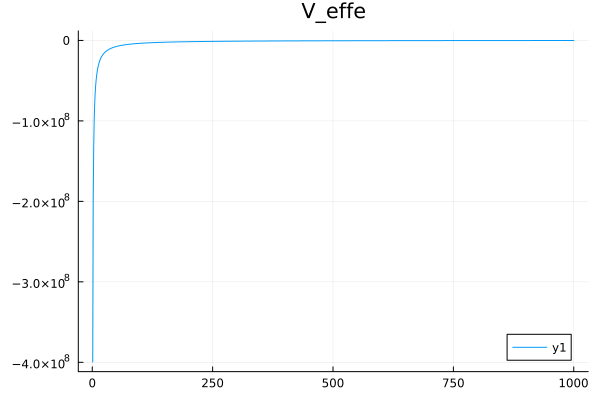

energy_interval (-0.5075365456597811, -0.2868684823294415)
E_intervals [(-0.4152840108226826, -0.41454599054398583)]


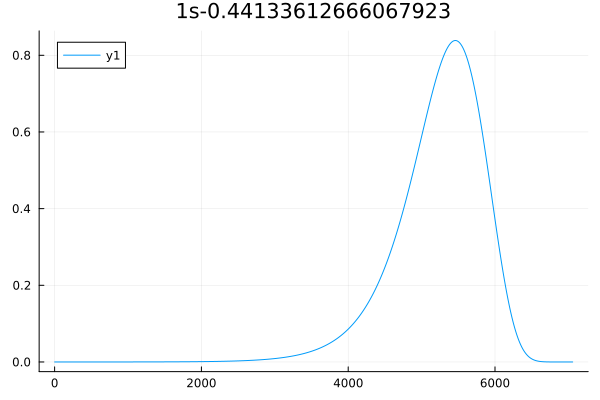

i_orbi.E -0.41430548285342916
--------------------------------
E_total -2.1244760178192057
*****************************************
1s


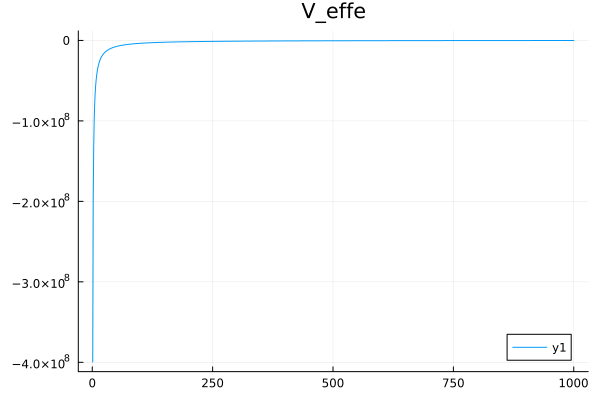

energy_interval (-0.4764513052814435, -0.26929856385472895)
E_intervals [(-0.3919274442310784, -0.3912346256978787)]


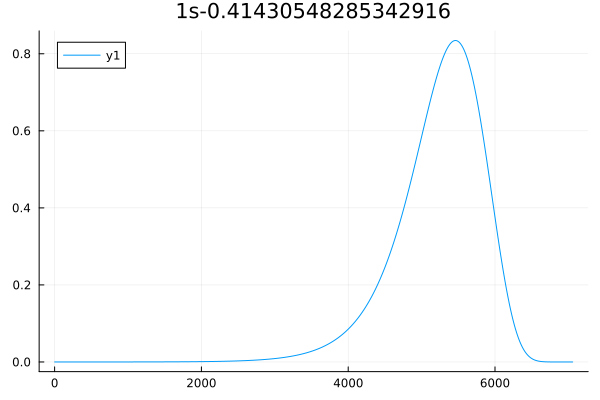

i_orbi.E -0.39094812676863827
--------------------------------
E_total -2.1128805693628356
*****************************************
1s


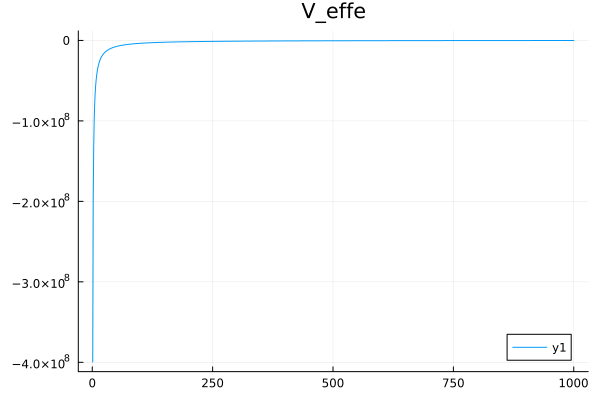

energy_interval (-0.44959034578393403, -0.2541162823996149)
E_intervals [(-0.37179297607579365, -0.37113921666648153)]


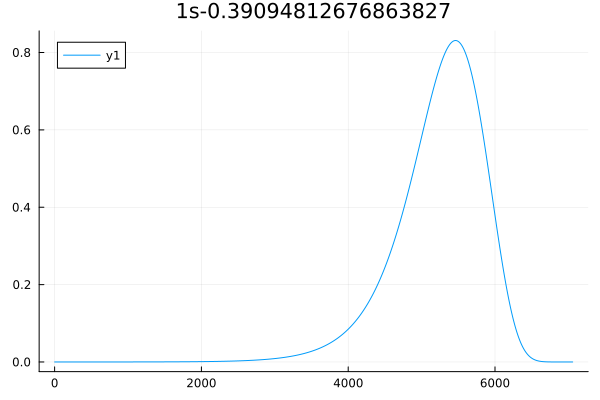

i_orbi.E -0.37074146190438445
--------------------------------
E_total -2.1033525440671017
*****************************************
1s


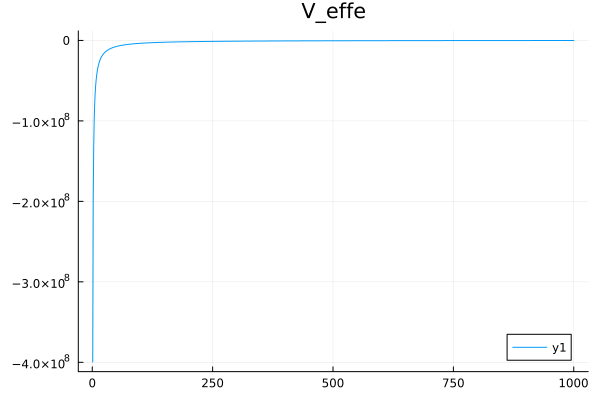

energy_interval (-0.4263526811900421, -0.2409819502378499)
E_intervals [(-0.3544362772085896, -0.35381630820874954)]


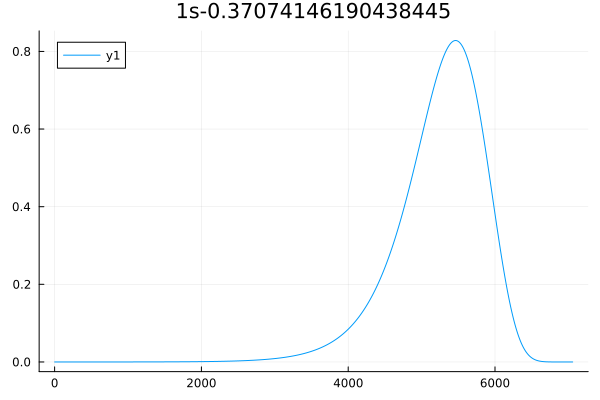

i_orbi.E -0.35323751427362265
--------------------------------
E_total -2.0954911657979305
*****************************************
1s


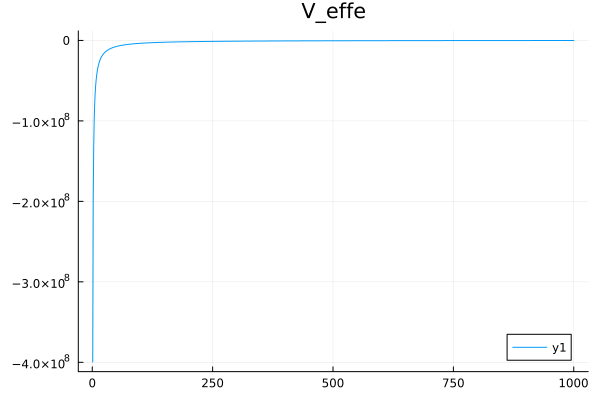

energy_interval (-0.40622314141466603, -0.22960438427785473)
E_intervals [(-0.3388835483926042, -0.33829285020820016)]


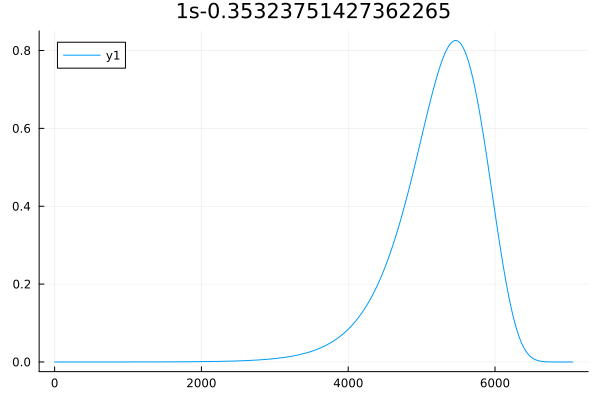

i_orbi.E -0.3380528277331992
--------------------------------
E_total -2.088979398732157
*****************************************
1s


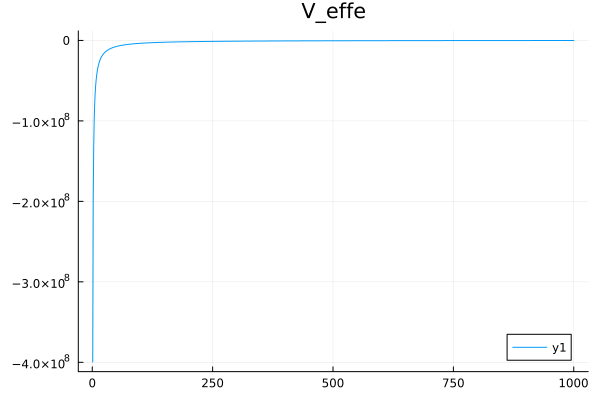

energy_interval (-0.3887607518931791, -0.2197343380265795)
E_intervals [(-0.32544650990970364, -0.3248812041777083)]


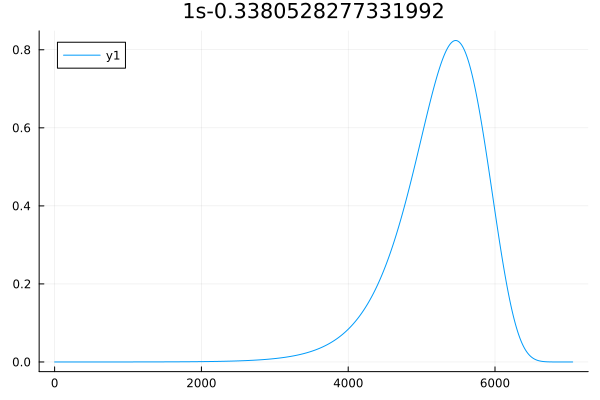

i_orbi.E -0.3248595659566881
--------------------------------
E_total -2.0835652519849526
*****************************************
1s


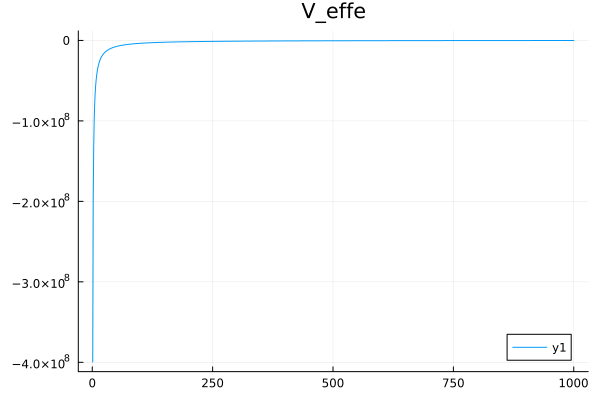

energy_interval (-0.3735885008501913, -0.21115871787184726)
E_intervals [(-0.31437496792497555, -0.31383172450364333)]


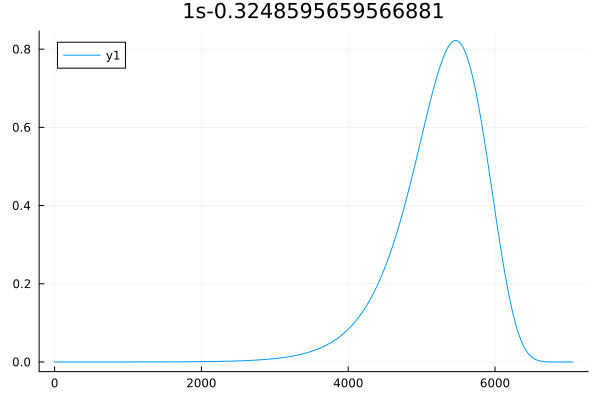

i_orbi.E -0.31337770456376485
--------------------------------
E_total -2.0790474598860382
*****************************************
1s


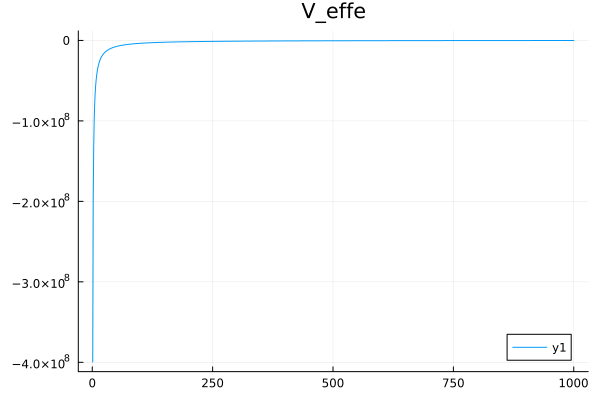

energy_interval (-0.3603843602483296, -0.20369550796644714)
E_intervals [(-0.30431176093675294, -0.30378771795253257)]


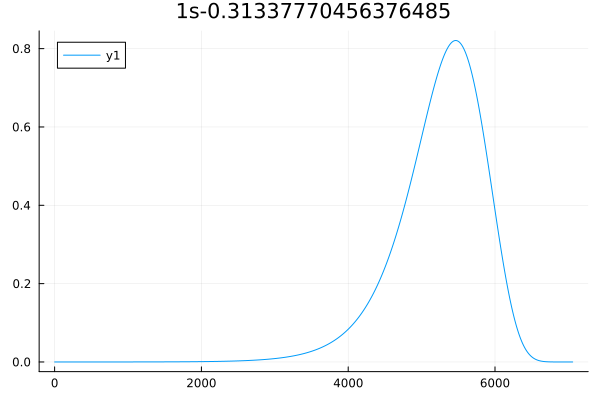

i_orbi.E -0.303368206736901
--------------------------------
E_total -2.075264503720443
*****************************************
1s


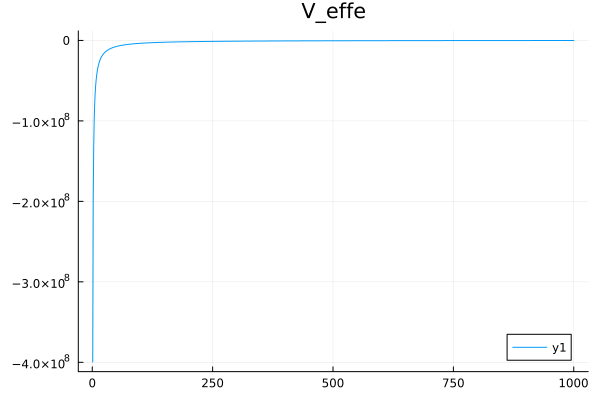

energy_interval (-0.3488734377474362, -0.19718933437898567)
E_intervals [(-0.2956064449257395, -0.2950991402321995)]


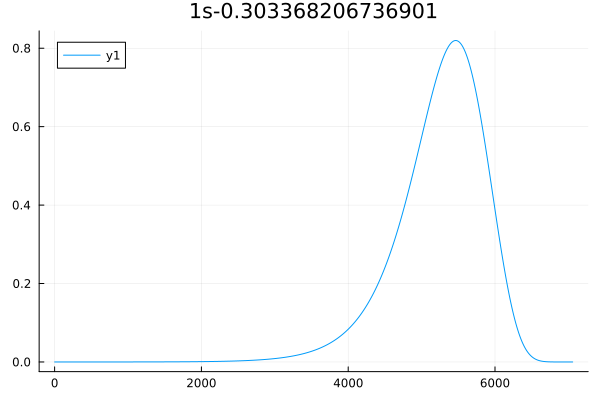

i_orbi.E -0.29462708370780966
--------------------------------
E_total -2.0720861725904745
*****************************************
1s


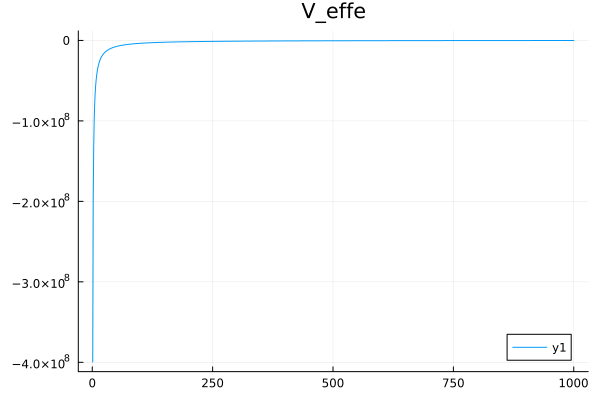

energy_interval (-0.3388211462639811, -0.19150760441007628)
E_intervals [(-0.28758165344523157, -0.2870889660142821)]


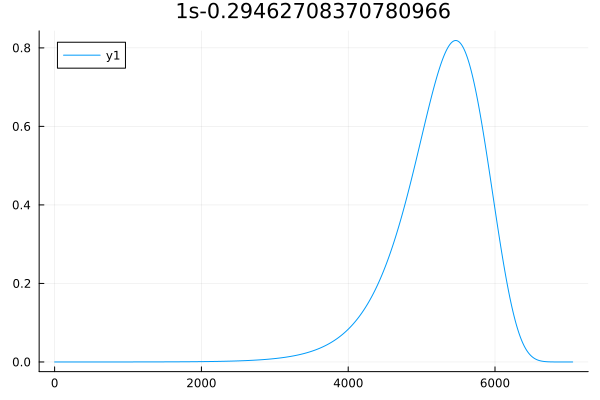

i_orbi.E -0.2869802481402135
--------------------------------
E_total -2.0694070490721934
*****************************************
1s


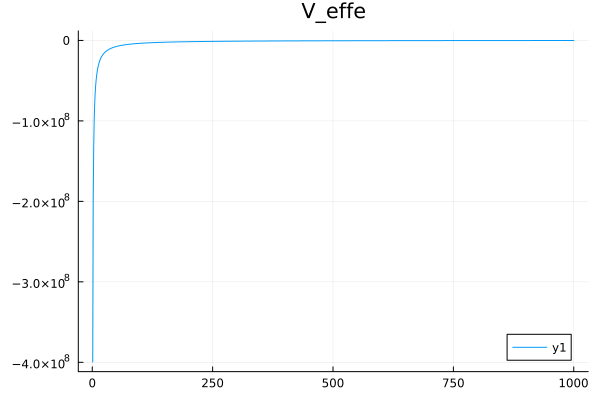

energy_interval (-0.33002728536124554, -0.1865371612911388)
E_intervals [(-0.28107747715003856, -0.28059757706953653)]


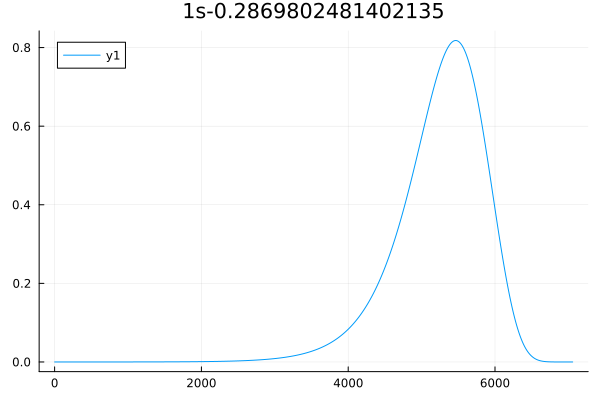

i_orbi.E -0.2802790742230881
--------------------------------
E_total -2.067141454166161
*****************************************
1s


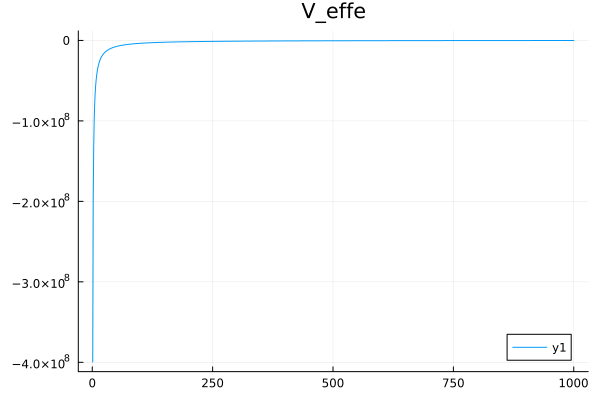

energy_interval (-0.3223209353565513, -0.1821813982450073)
E_intervals [(-0.2749828308473007, -0.27451413674324865)]


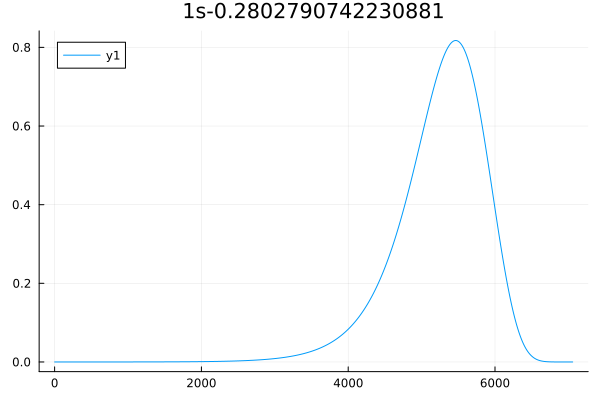

i_orbi.E -0.2743965837443159
--------------------------------
E_total -2.065219501360997
*****************************************
1s


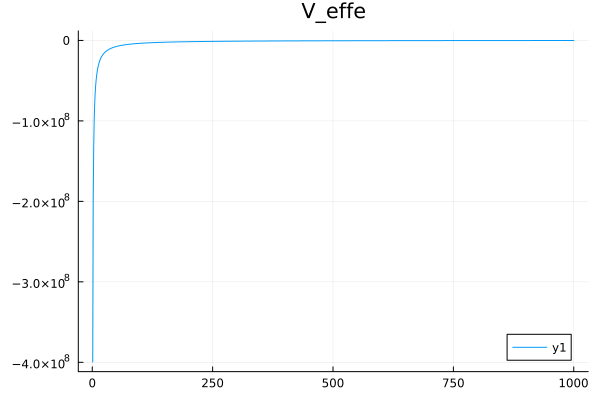

energy_interval (-0.3155560713059633, -0.17835777943380535)
E_intervals [(-0.27012921212421204, -0.26967035496076)]


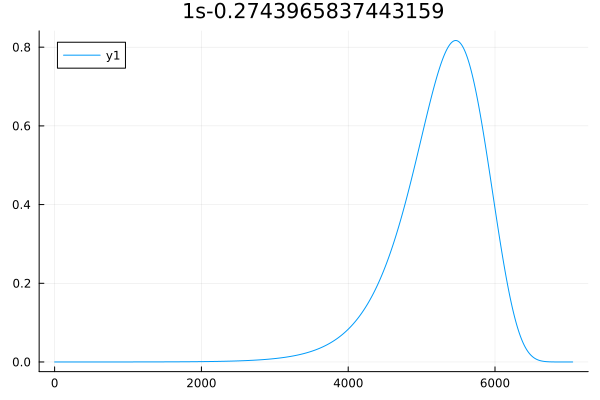

i_orbi.E -0.2692241829102355
--------------------------------
E_total -2.0635839974210133
*****************************************
1s


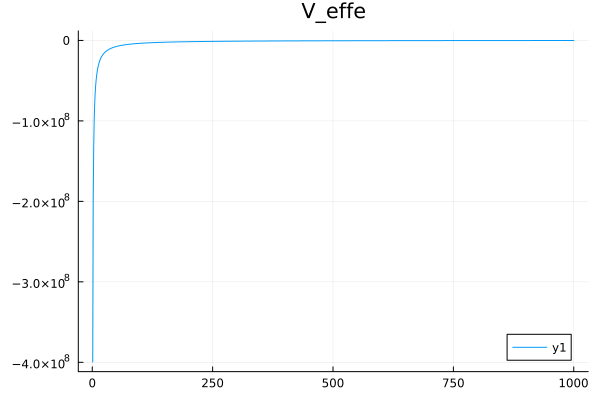

energy_interval (-0.3096078103467708, -0.17499571889165305)
E_intervals [(-0.2654874593012807, -0.2650372516375512)]


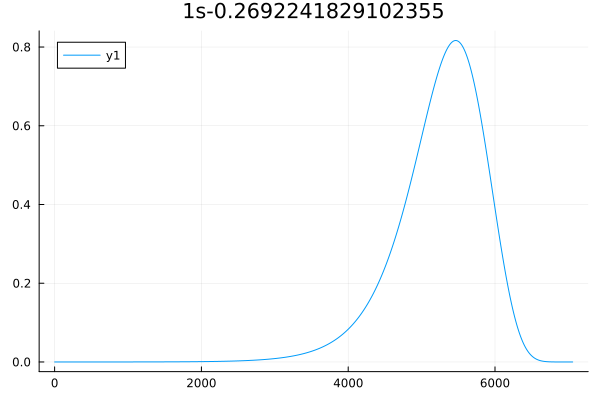

i_orbi.E -0.26466888038749425
--------------------------------
E_total -2.0621879934164555
*****************************************
1s


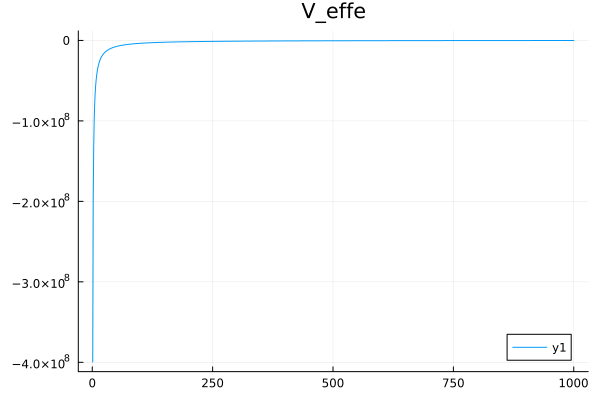

energy_interval (-0.3043692124456184, -0.17203477225187128)
E_intervals [(-0.2614379726503225, -0.26099538254934007)]


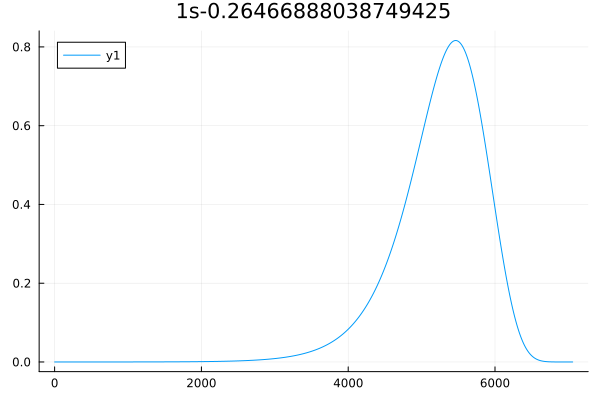

i_orbi.E -0.2606509229981018
--------------------------------
E_total -2.0609928385380574
*****************************************
1s


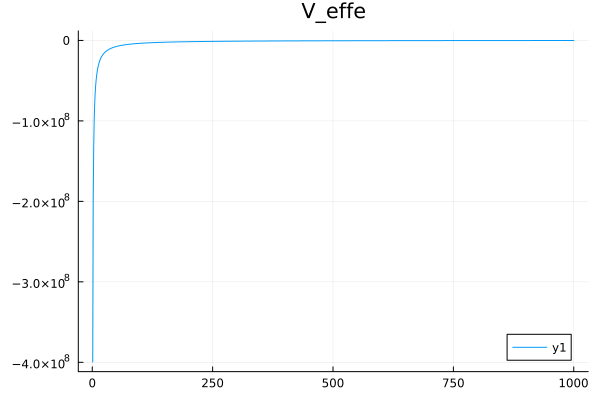

energy_interval (-0.29974856144781703, -0.16942309994876614)
E_intervals [(-0.25790493501333916, -0.2574690639046467)]


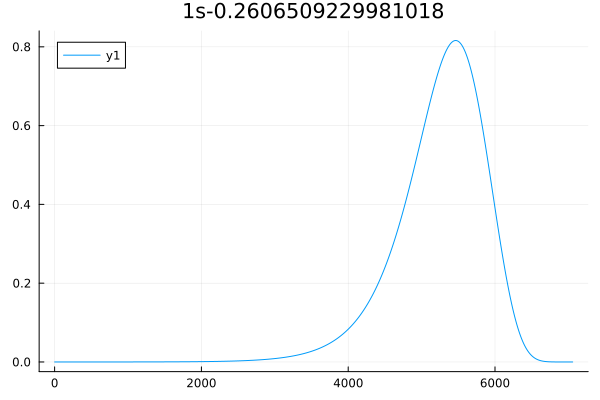

i_orbi.E -0.2571017915988567
--------------------------------
E_total -2.059966625486373
*****************************************
1s


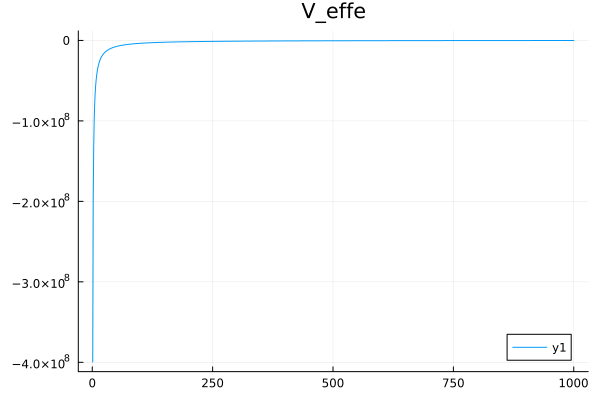

energy_interval (-0.29566706033868523, -0.16711616453925687)
E_intervals [(-0.2543931941288353, -0.2539632580224827)]


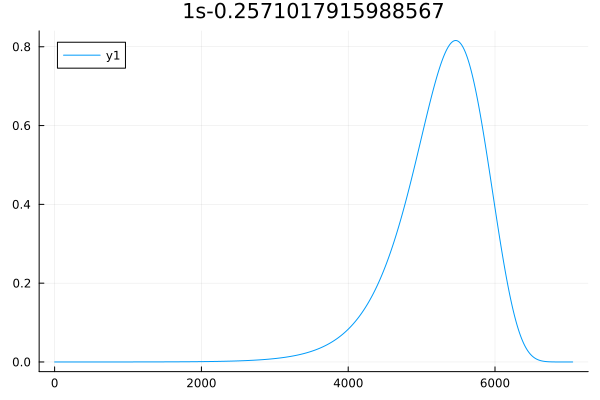

i_orbi.E -0.2539625057851385
--------------------------------
E_total -2.05908294300409
*****************************************
1s


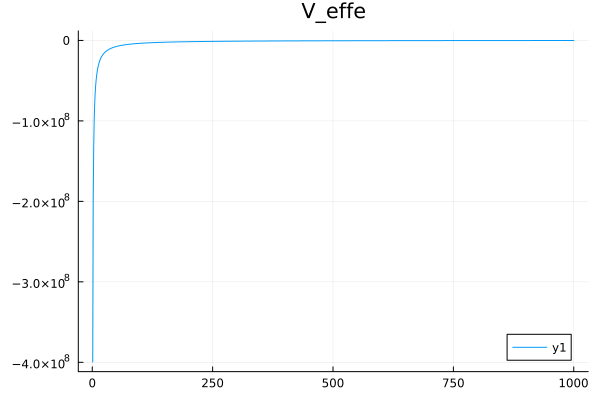

energy_interval (-0.2920568816529093, -0.16507562876034004)
E_intervals [(-0.2517116675231632, -0.25128698105863956)]


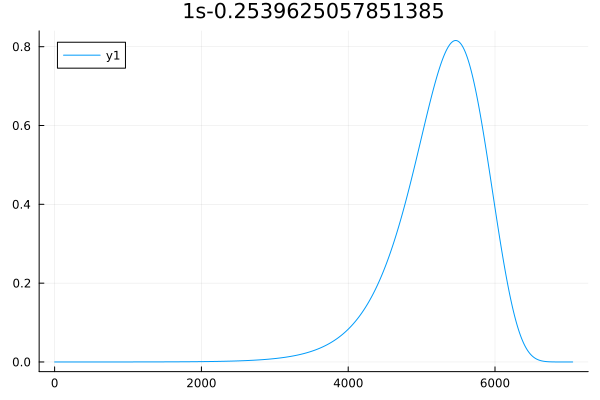

i_orbi.E -0.251182192016435
--------------------------------
E_total -2.0583198709356703
*****************************************
1s


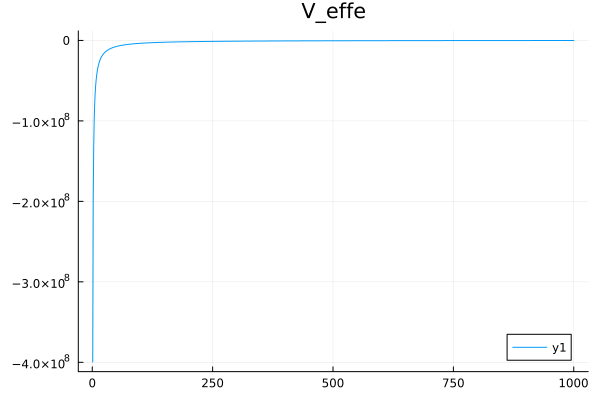

energy_interval (-0.28885952081890026, -0.16326842481068277)
E_intervals [(-0.2493760324417349, -0.24895599533133952)]


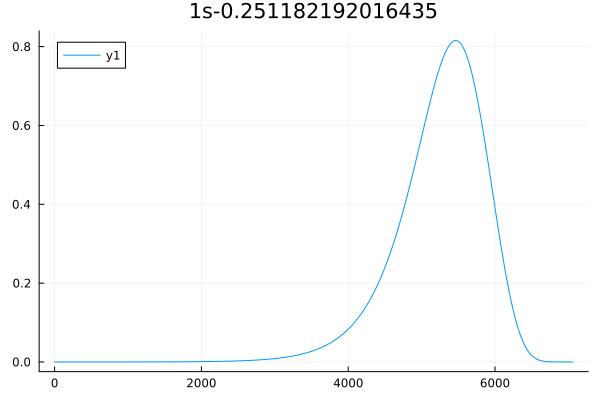

i_orbi.E -0.24871687543061224
--------------------------------
E_total -2.057659167943571
*****************************************
1s


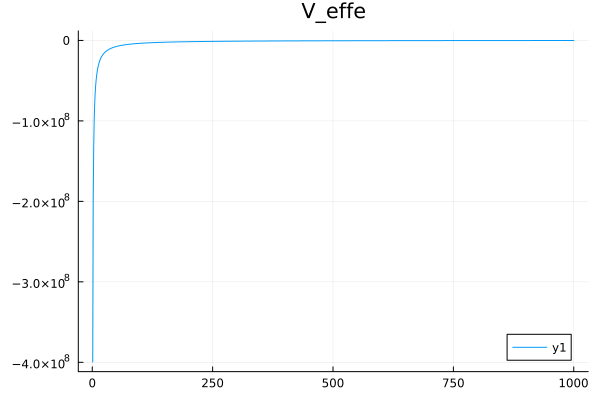

energy_interval (-0.2860244067452041, -0.16166596902989797)
E_intervals [(-0.24734435755616238, -0.24692844304875333)]


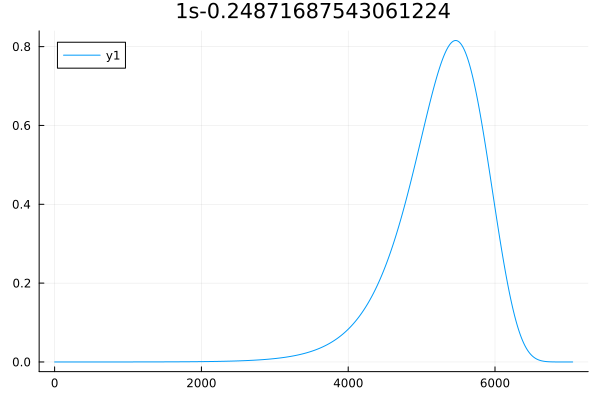

i_orbi.E -0.24652846088933267
--------------------------------
E_total -2.0570856130621413
*****************************************
1s


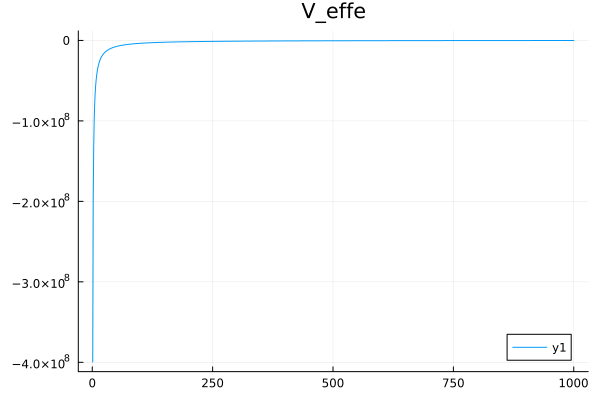

energy_interval (-0.28350773002273255, -0.16024349957806625)
E_intervals [(-0.2451680195499768, -0.24475576459865686)]


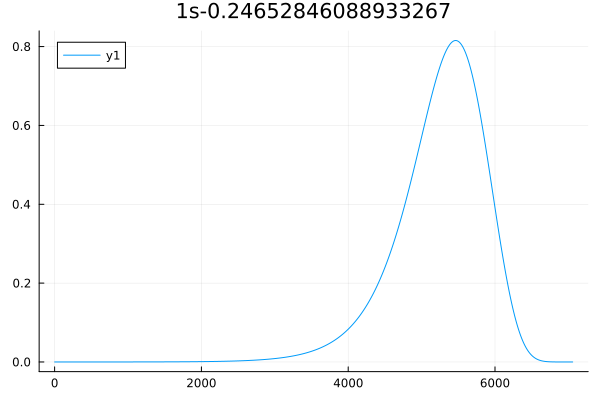

i_orbi.E -0.24458387361226017
--------------------------------
E_total -2.056586470636196
*****************************************
1s


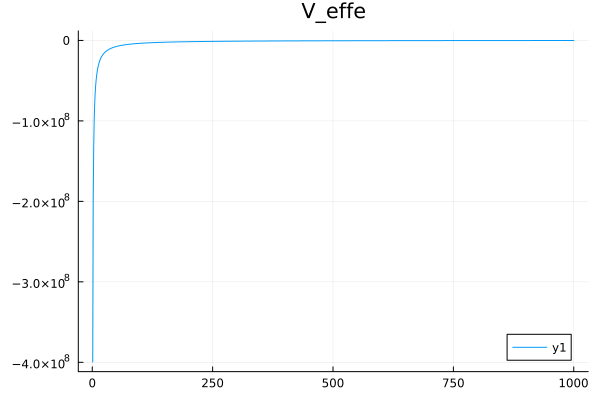

energy_interval (-0.2812714546540992, -0.1589795178479691)
E_intervals [(-0.24364316640605915, -0.2432341632729283)]


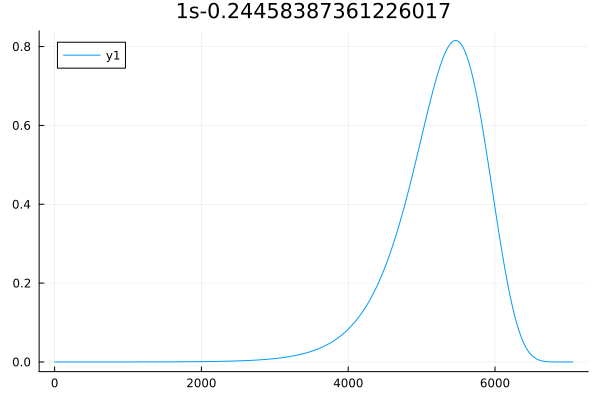

i_orbi.E -0.24285433407540877
--------------------------------
E_total -2.056151054580527
*****************************************
1s


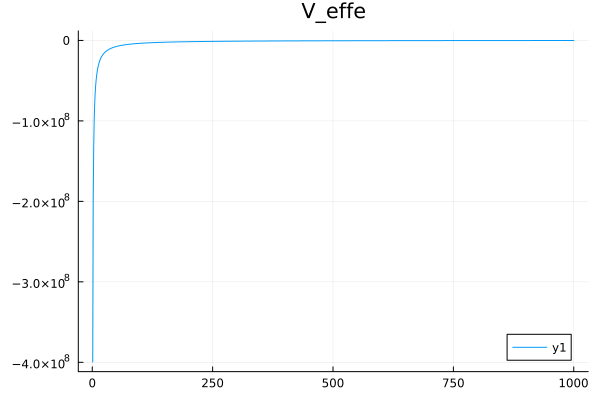

energy_interval (-0.2792824841867201, -0.15785531714901568)
E_intervals [(-0.2419202789443495, -0.24151416801780198)]


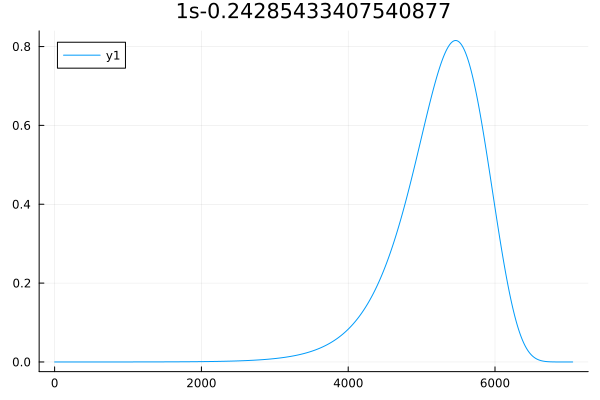

i_orbi.E -0.24131474566695924
--------------------------------
E_total -2.055770372830229
*****************************************
1s


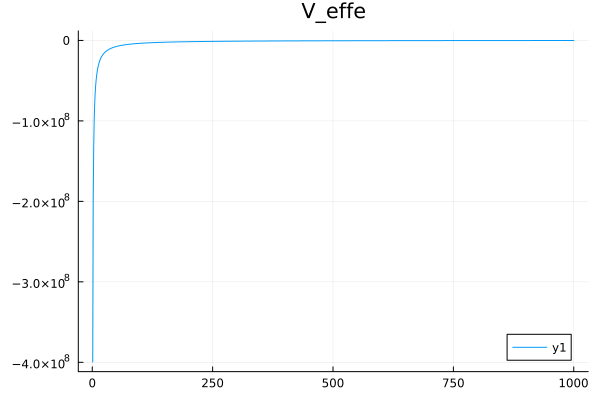

energy_interval (-0.27751195751700314, -0.1568545846835235)
E_intervals [(-0.24038661202977862, -0.23998307566578705)]


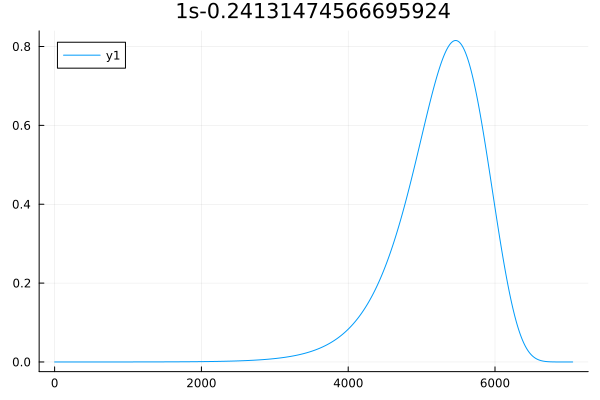

i_orbi.E -0.2399431769275054
--------------------------------
E_total -2.0554368366970355
*****************************************
1s


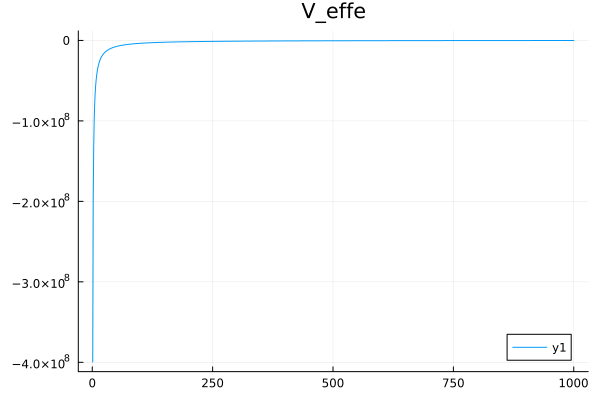

energy_interval (-0.2759346534666312, -0.15596306500287854)
E_intervals [(-0.23942156132548909, -0.23902031855470732)]


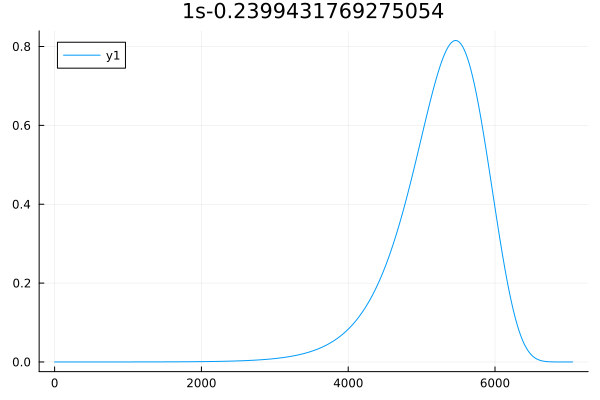

i_orbi.E -0.23872042308033242
--------------------------------
E_total -2.0551440228645967
*****************************************
1s


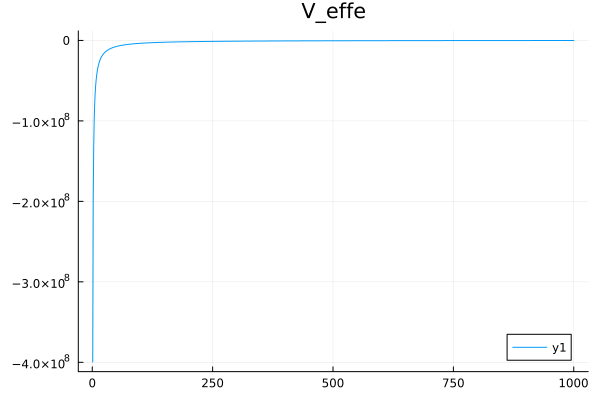

energy_interval (-0.27452848654238227, -0.15516827500221608)
E_intervals [(-0.23820146563885342, -0.2378022676069465)]


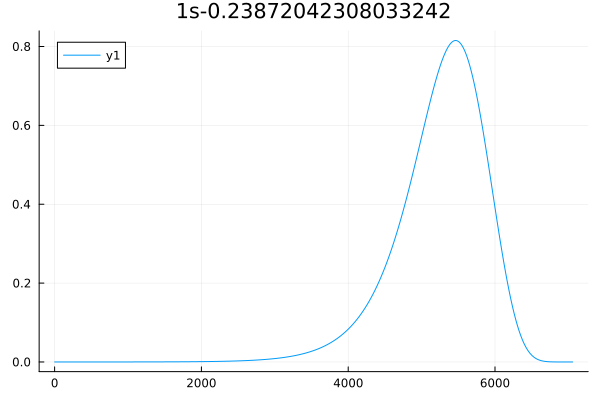

i_orbi.E -0.23762963402432405
--------------------------------
E_total -2.0548864781496325
*****************************************
1s


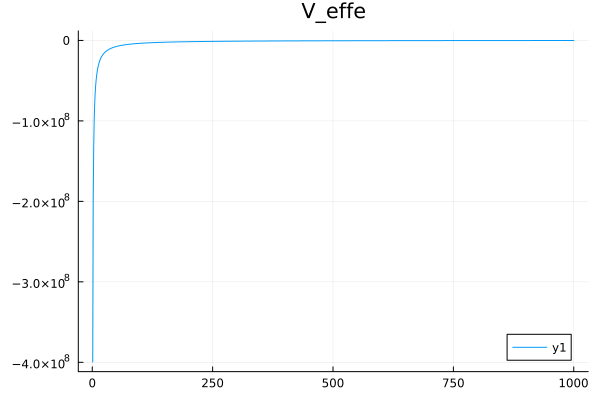

energy_interval (-0.27327407912797264, -0.15445926211581062)
E_intervals [(-0.2371130478634016, -0.23671567389346126)]


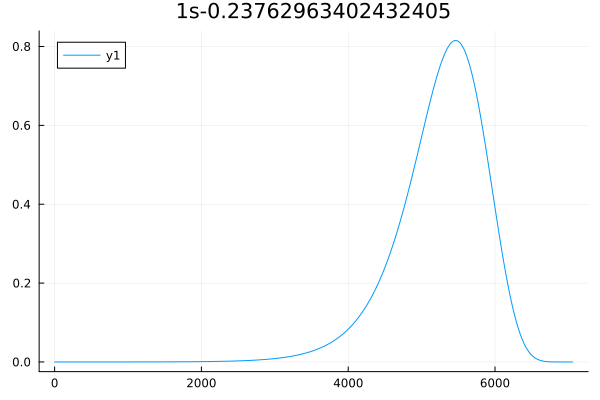

i_orbi.E -0.2366559980570416
--------------------------------
E_total -2.054659559058662
*****************************************
1s


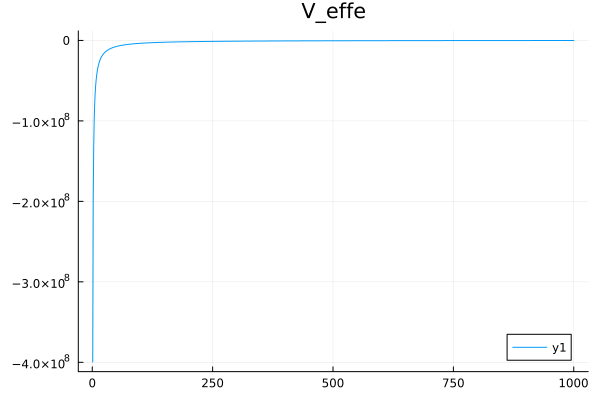

energy_interval (-0.27215439776559786, -0.15382639873707704)
E_intervals [(-0.23653727431219695, -0.23614152849604805)]


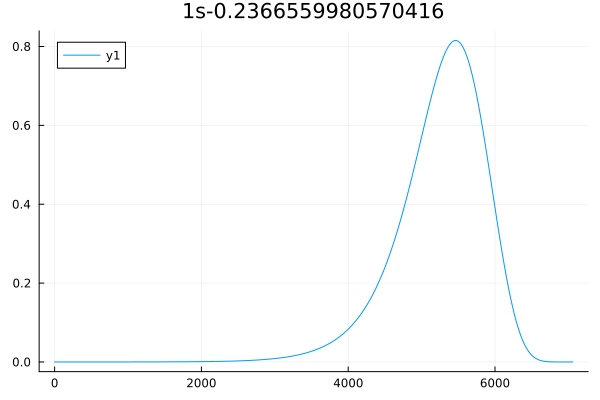

i_orbi.E -0.23578647236587102
--------------------------------
E_total -2.0544592996932343
*****************************************
1s


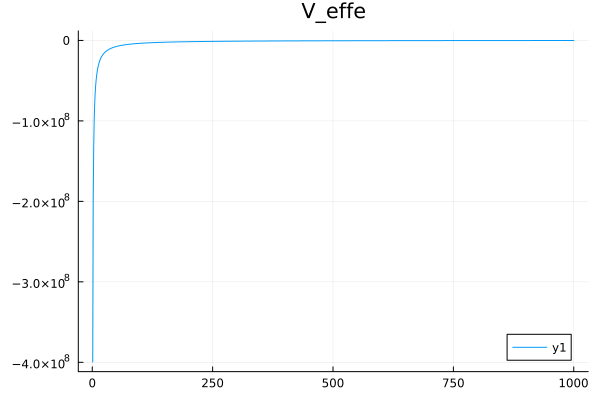

energy_interval (-0.27115444322075166, -0.15326120703781618)
E_intervals [(-0.23566818483792829, -0.23527389307811913)]


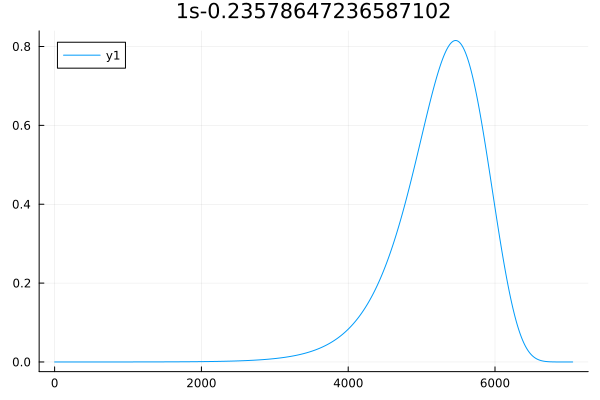

i_orbi.E -0.23500955281346075
--------------------------------
E_total -2.054282302783415
*****************************************
1s


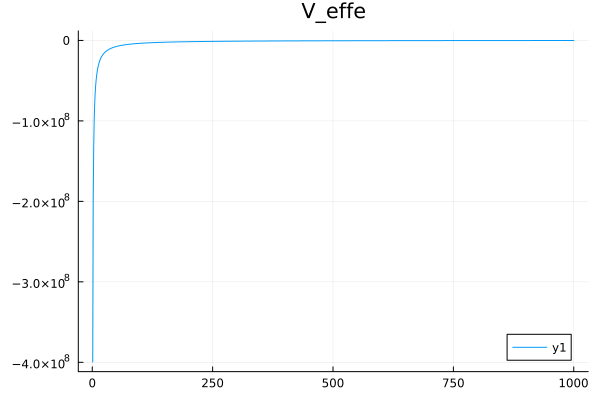

energy_interval (-0.27026098573547985, -0.1527562093287495)
E_intervals [(-0.23489165504449078, -0.23449866248125756)]


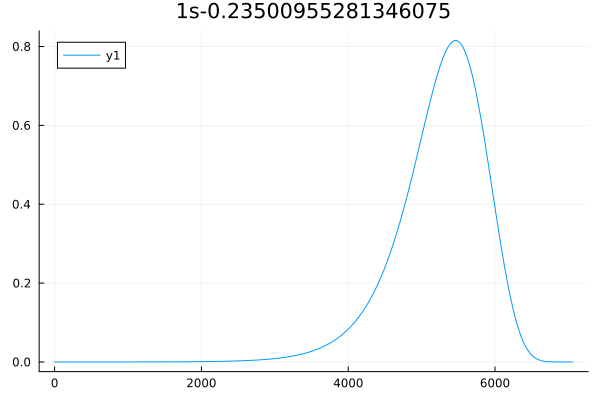

i_orbi.E -0.23431507678751515
--------------------------------
E_total -2.054125649611466
*****************************************
1s


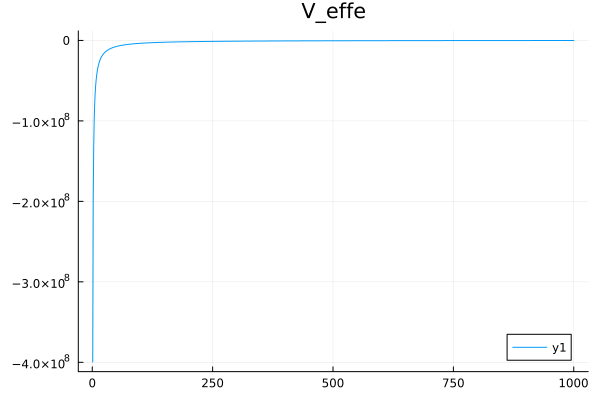

energy_interval (-0.2694623383056424, -0.15230479991188484)
E_intervals [(-0.2341975274178893, -0.23380569618580316)]


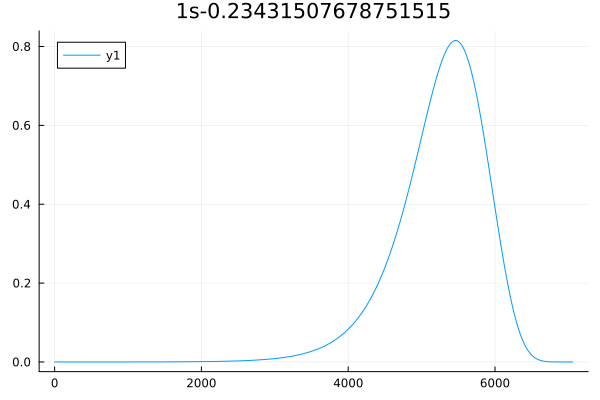

i_orbi.E -0.2336940539251384
--------------------------------
E_total -2.0539868253886078
*****************************************
1s


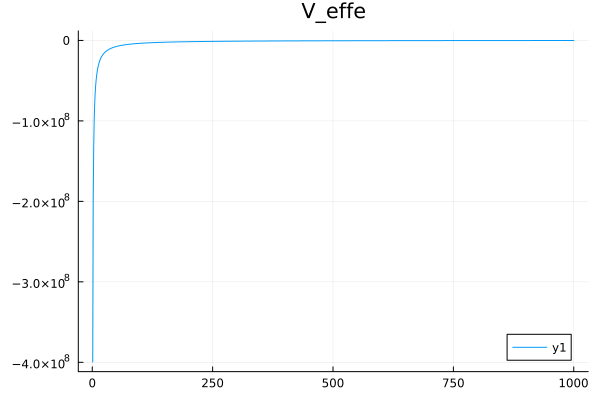

energy_interval (-0.26874816201390916, -0.15190113505133995)
E_intervals [(-0.2335768161054435, -0.23318602337312722)]


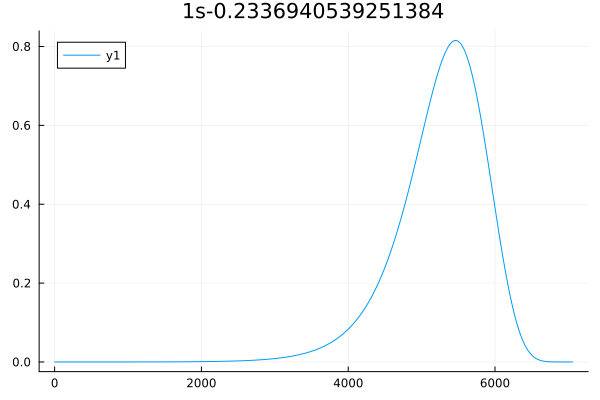

i_orbi.E -0.23313852038468993
--------------------------------
E_total -2.0538636572876228
*****************************************
1s


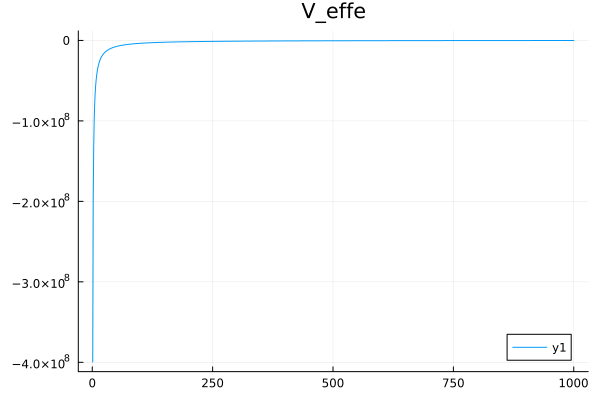

energy_interval (-0.2681092984423934, -0.15154003825004847)
E_intervals [(-0.2334114250072138, -0.2330215612607511)]


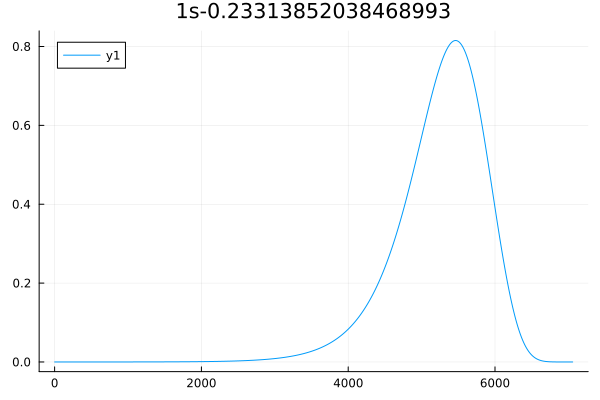

i_orbi.E -0.23264141305695293
--------------------------------
E_total -2.0537542628587615
*****************************************
1s


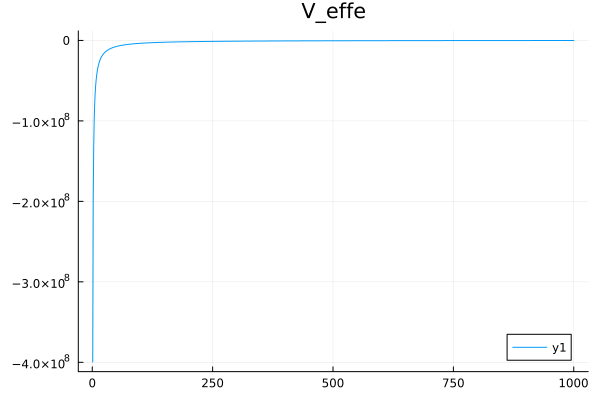

energy_interval (-0.2675376250154959, -0.1512169184870194)
E_intervals [(-0.2329137357812671, -0.23252470331796116)]


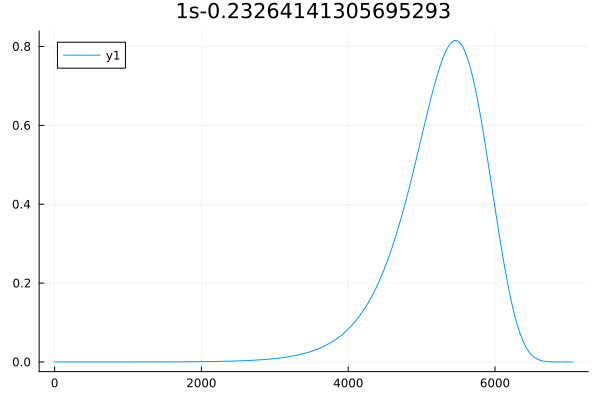

i_orbi.E -0.23219646070174016
--------------------------------
E_total -2.053657006976601
*****************************************
1s


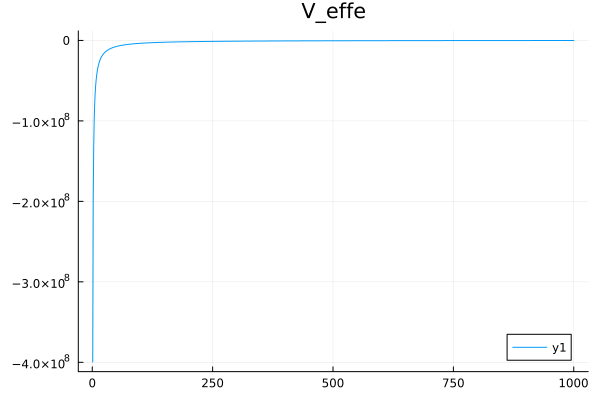

energy_interval (-0.2670259298070012, -0.1509276994561311)
E_intervals [(-0.23246826257881578, -0.23207997418299348)]


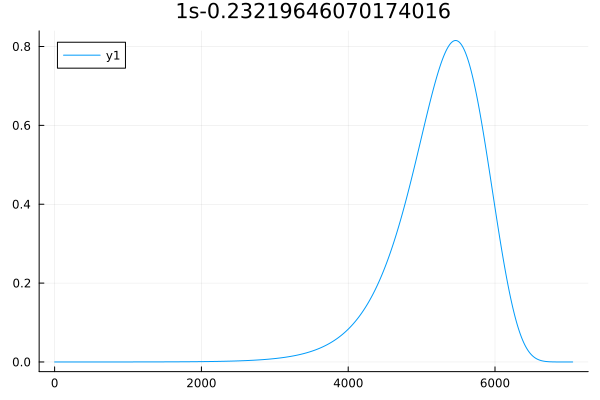

i_orbi.E -0.2317980894900149
--------------------------------
E_total -2.053570465808923
*****************************************
1s


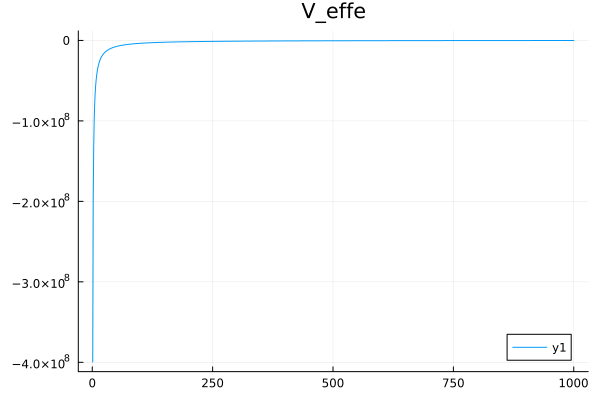

energy_interval (-0.2665678029135171, -0.1506687581685097)
E_intervals [(-0.2320694250462741, -0.23168180282304665)]


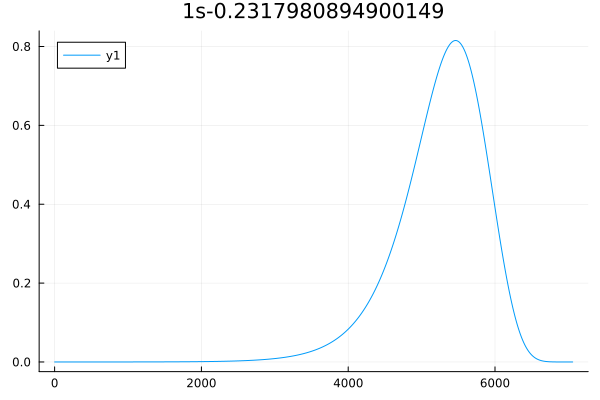

i_orbi.E -0.2314413408407613
--------------------------------
E_total -2.053493396578476
*****************************************
1s


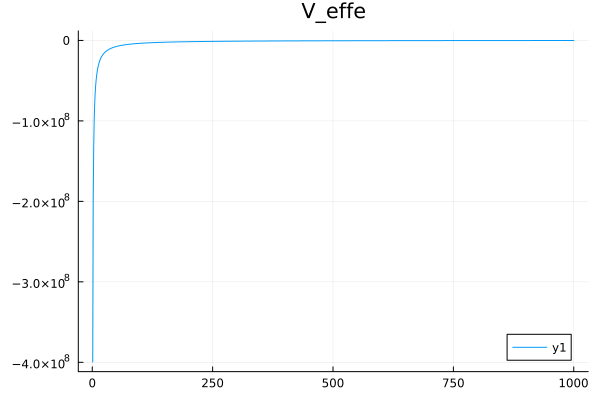

energy_interval (-0.26615754196687547, -0.15043687154649485)
E_intervals [(-0.23171225879826718, -0.23132523314468734)]


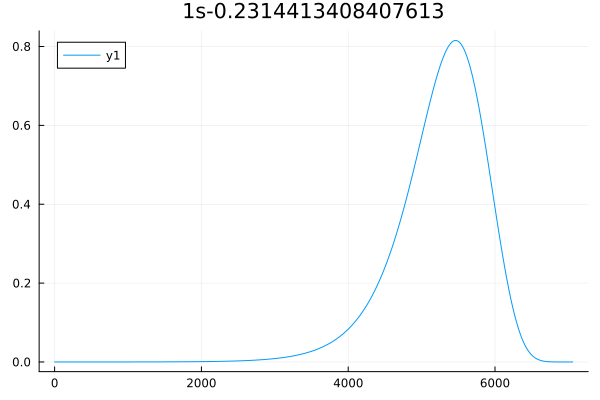

i_orbi.E -0.23112179977935474
--------------------------------
E_total -2.0534247121097584
*****************************************
1s


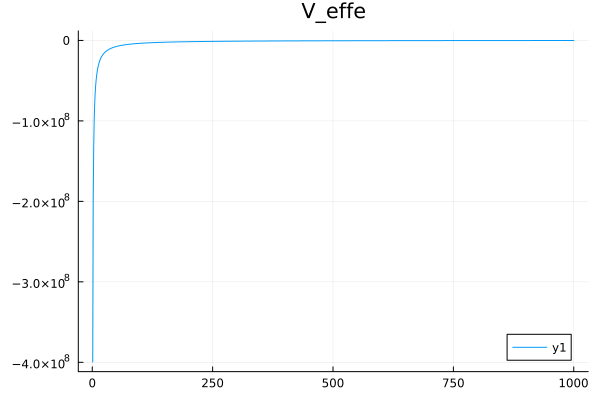

energy_interval (-0.26579006974625796, -0.15022916985658058)
E_intervals [(-0.23139234369213996, -0.2310058523881611)]


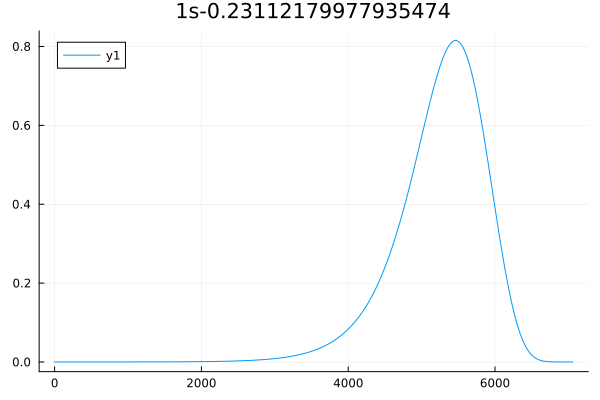

i_orbi.E -0.23083553232733234
--------------------------------
E_total -2.053363459342272
*****************************************
1s


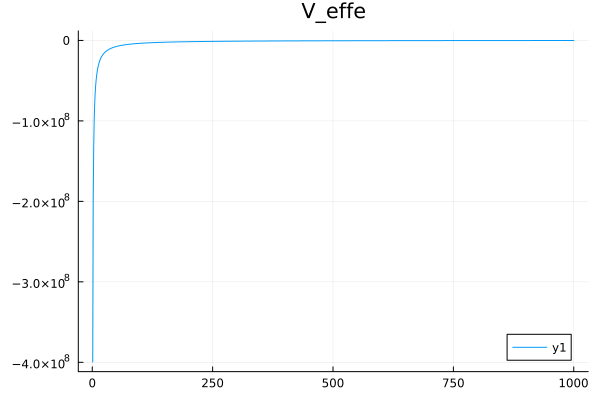

energy_interval (-0.26546086217643217, -0.15004309601276603)
E_intervals [(-0.23110574114443788, -0.23071972854857278)]


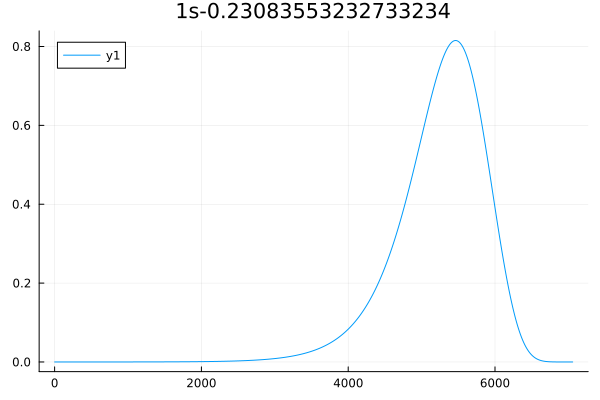

i_orbi.E -0.2305790306644701
--------------------------------
E_total -2.0533088011344303
*****************************************
1s


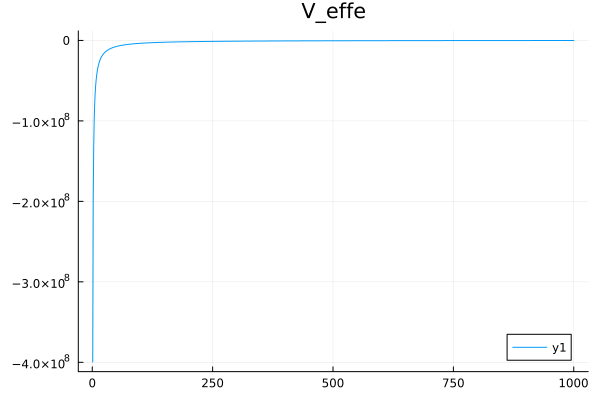

energy_interval (-0.26516588526414064, -0.14987636993190556)
E_intervals [(-0.23084893922879307, -0.23046335556547456)]


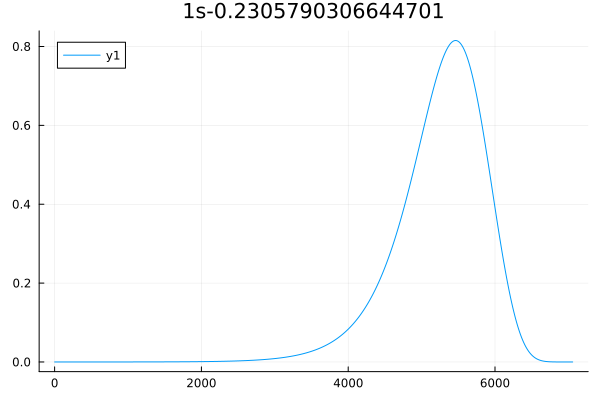

i_orbi.E -0.23034916500019206
--------------------------------
E_total -2.0532600008087694
*****************************************
1s


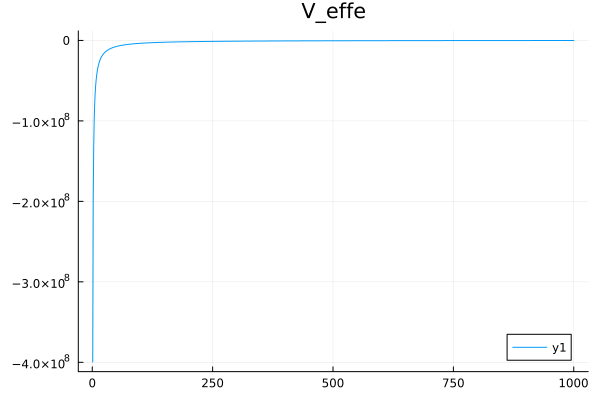

energy_interval (-0.26490153975022085, -0.14972695725012486)
E_intervals [(-0.23061880449099495, -0.23023360521841937)]


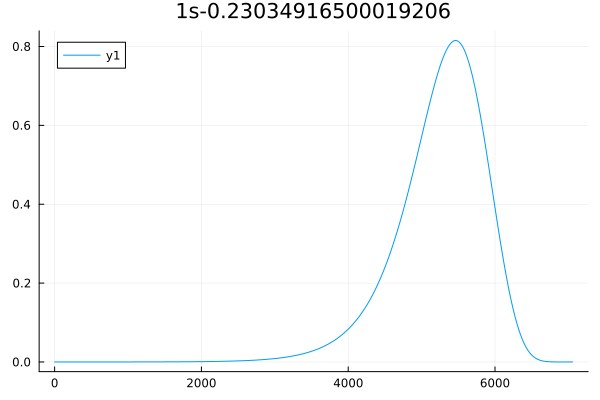

i_orbi.E -0.23014314125123678
--------------------------------
E_total -2.0532164089840736
*****************************************
1s


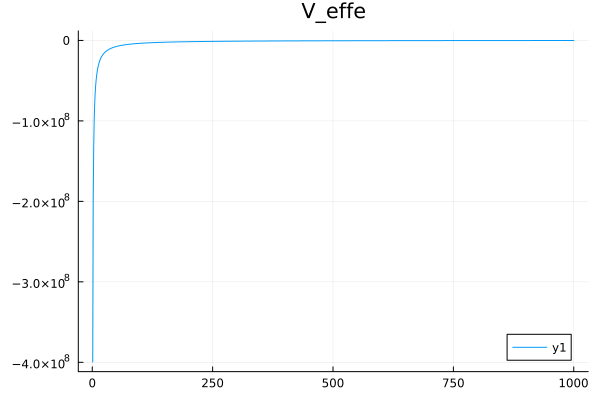

energy_interval (-0.2646646124389223, -0.1495930418133039)
E_intervals [(-0.23041253957711616, -0.23002768482585992)]


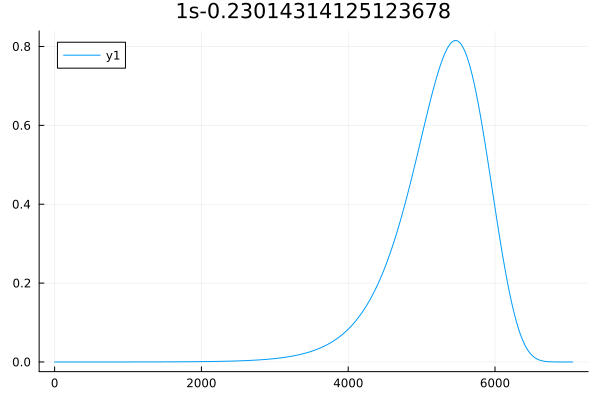

i_orbi.E -0.22995846375804876
--------------------------------
E_total -2.0531774523211057
*****************************************
1s


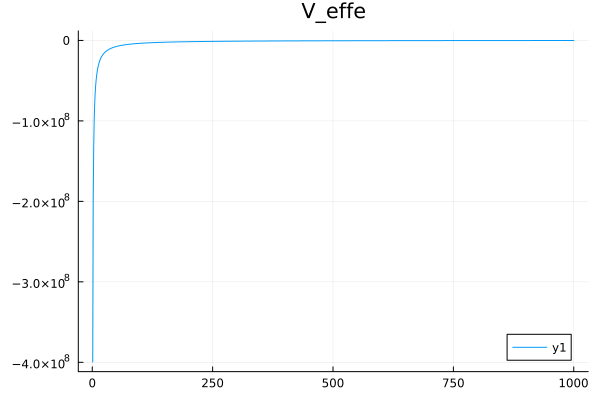

energy_interval (-0.26445223332175605, -0.1494730014427317)
E_intervals [(-0.23022764590626052, -0.22984309998024371)]


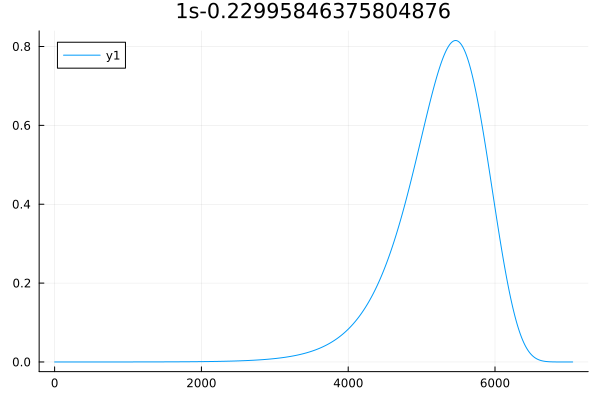

i_orbi.E -0.22979290238560784
--------------------------------
E_total -2.0531426238765373
*****************************************
1s


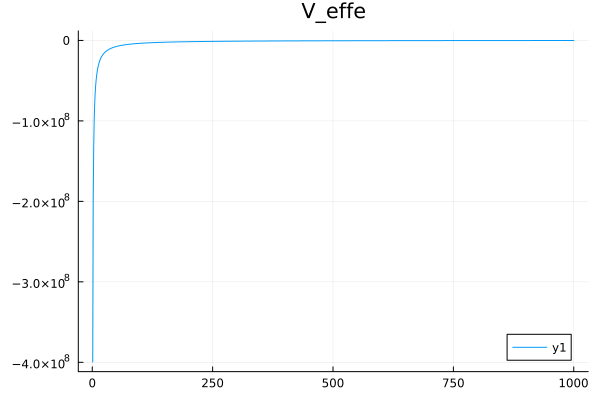

energy_interval (-0.264261837743449, -0.1493653865506451)
E_intervals [(-0.23006189073288197, -0.2296776216653475)]


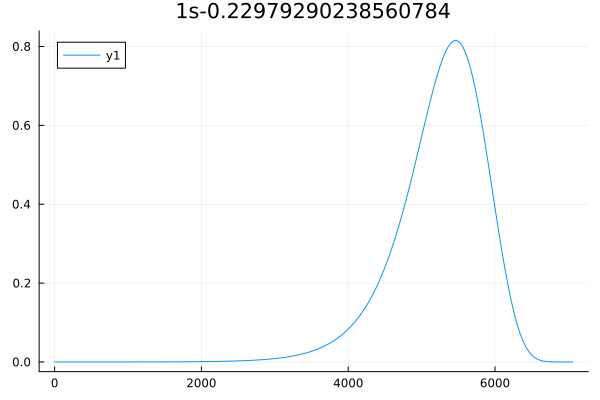

i_orbi.E -0.22964446344733488
--------------------------------
E_total -2.0531114748087953
*****************************************
1s


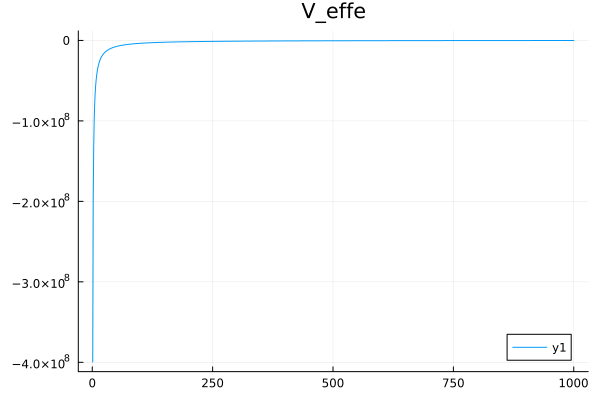

energy_interval (-0.2640911329644351, -0.1492689012407677)
E_intervals [(-0.2299132780366545, -0.22952925719476933)]


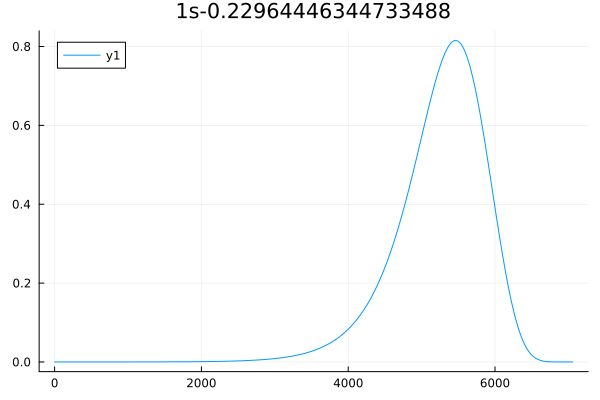

i_orbi.E -0.22951136397167443
--------------------------------
E_total -2.053083607226213
*****************************************
1s


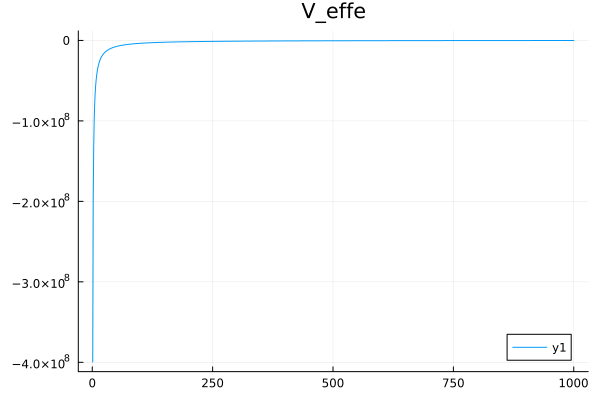

energy_interval (-0.2639380685674256, -0.1491823865815884)
E_intervals [(-0.22978002275893222, -0.22939622449142108)]


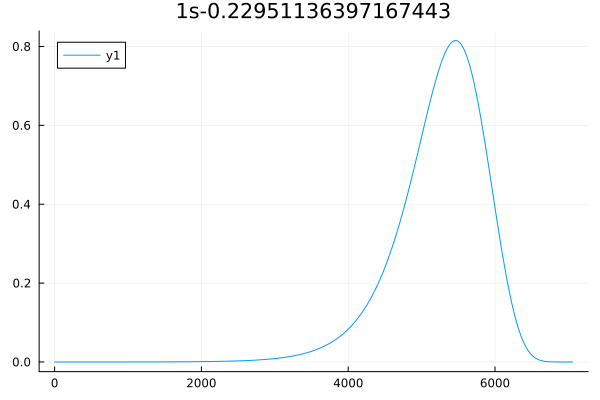

i_orbi.E -0.22939200889741668
--------------------------------
E_total -2.053058668003704
*****************************************
1s


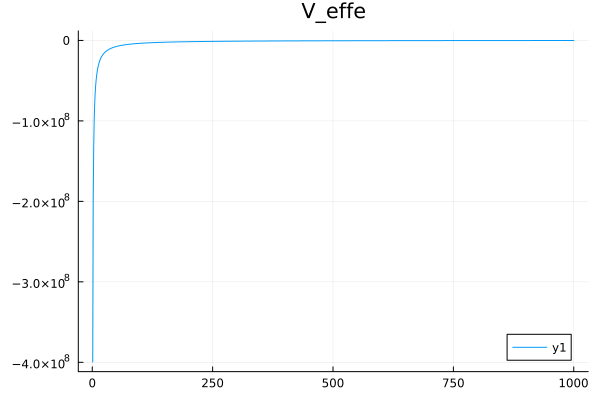

energy_interval (-0.26380081023202917, -0.14910480578332086)
E_intervals [(-0.23004412664846285, -0.22966052797137687)]


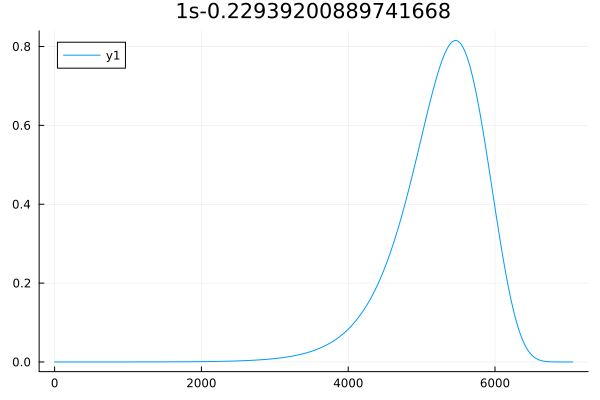

i_orbi.E -0.2292849708398021
--------------------------------
E_total -2.0530363434208185
*****************************************
1s


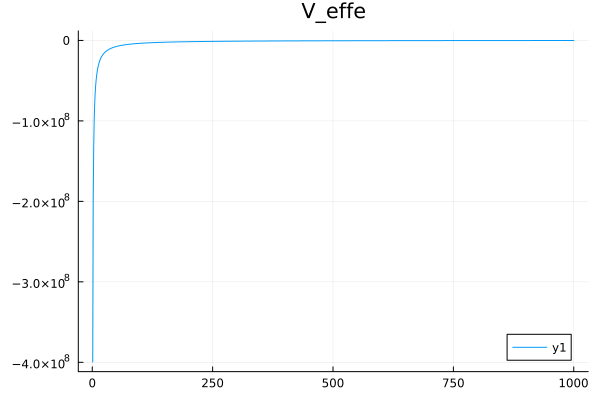

energy_interval (-0.2636777164657724, -0.14903523104587135)
E_intervals [(-0.22993678430205572, -0.2295533646183771)]


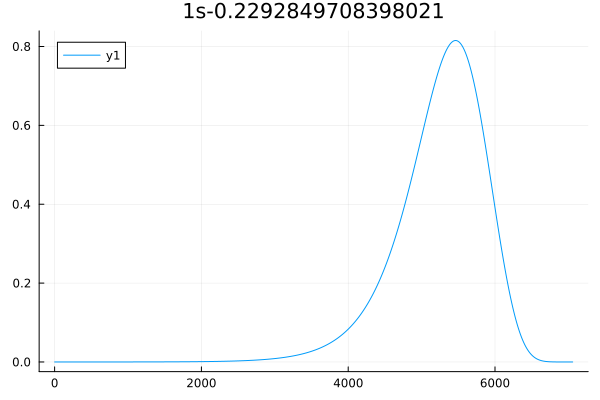

i_orbi.E -0.22918897211857936
--------------------------------
E_total -2.0530163545015436
*****************************************
1s


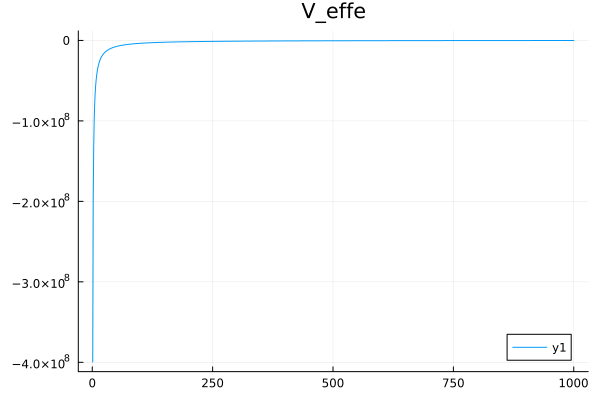

energy_interval (-0.2635673179363663, -0.1489728318770766)
E_intervals [(-0.22984051267476932, -0.22945725352406937)]


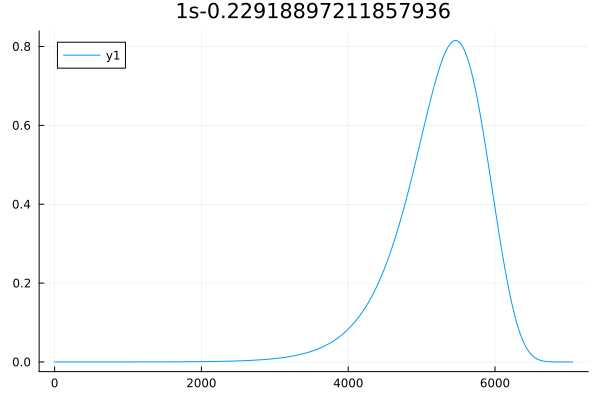

i_orbi.E -0.2291028687787878
--------------------------------
E_total -2.0529984529525436
*****************************************
1s


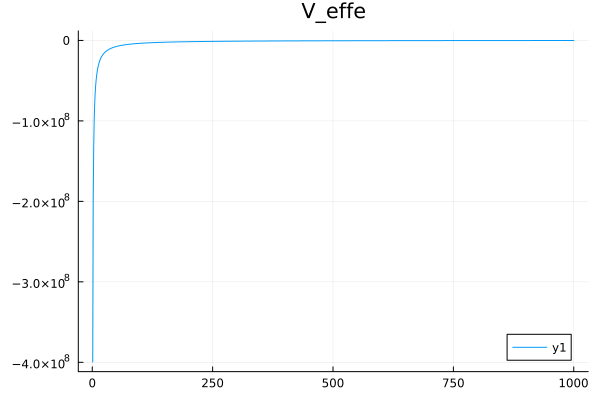

energy_interval (-0.263468299095606, -0.14891686470621207)
E_intervals [(-0.22975416455959707, -0.22937104939441516)]


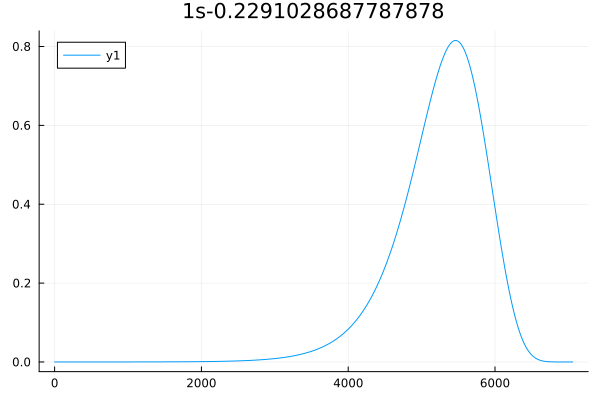

i_orbi.E -0.22902563637098478
--------------------------------
E_total -2.052982417616012
*****************************************
1s


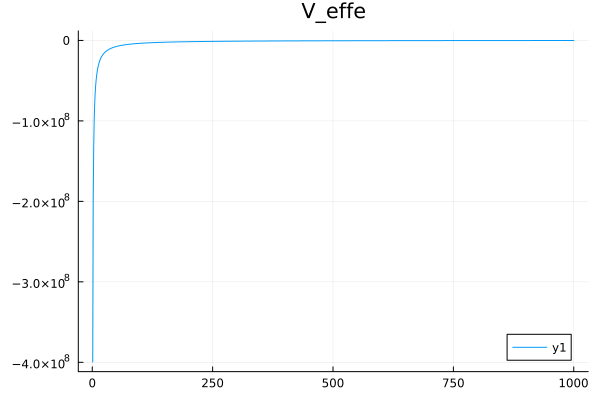

energy_interval (-0.2633794818266325, -0.1488666636411401)
E_intervals [(-0.2296767125947819, -0.2292937265807836)]


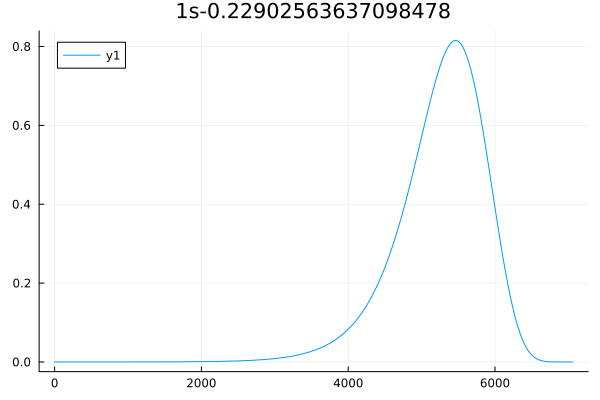

i_orbi.E -0.22895635728652475
--------------------------------
E_total -2.052968051364084
*****************************************
1s


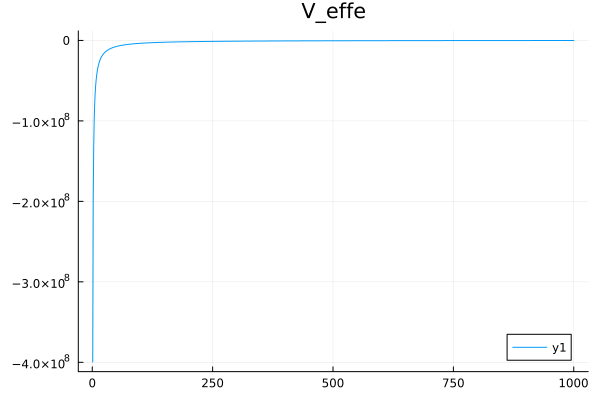

energy_interval (-0.26329981087950344, -0.1488216322362411)
E_intervals [(-0.2296072365630918, -0.22922436640040528)]


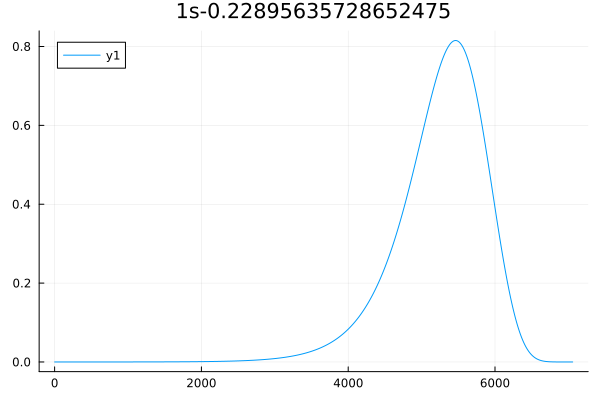

i_orbi.E -0.2288942094697362
--------------------------------
E_total -2.052955178374818
*****************************************
1s


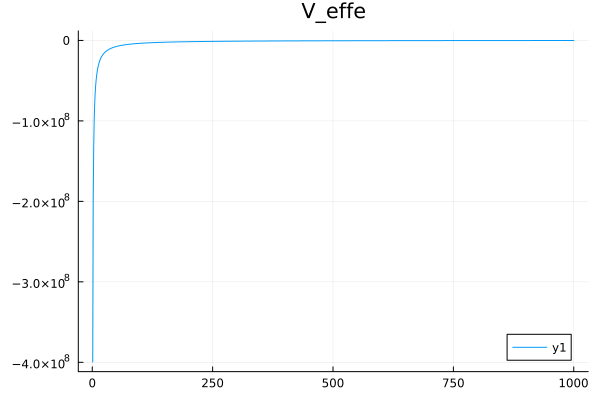

energy_interval (-0.26322834089019664, -0.14878123615532854)
E_intervals [(-0.2295449120719077, -0.22916214583533623)]


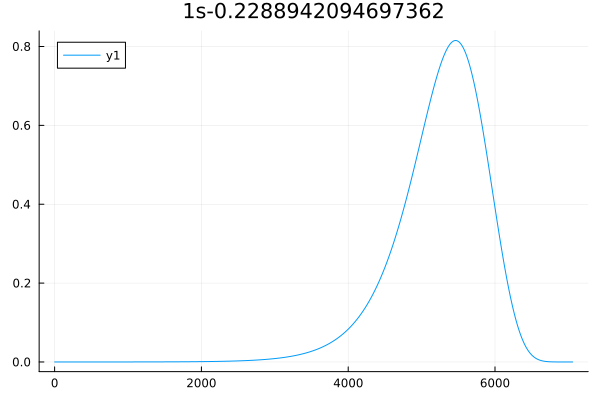

i_orbi.E -0.22883845635054534
--------------------------------
E_total -2.0529436417381586
*****************************************
1s


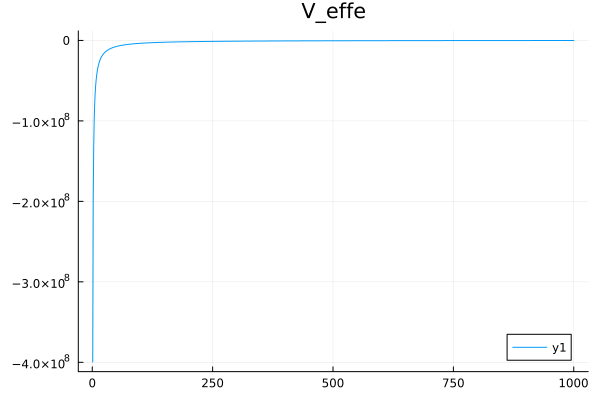

energy_interval (-0.2631642248031271, -0.14874499662785448)
E_intervals [(-0.22948900045722748, -0.22910632745329682)]


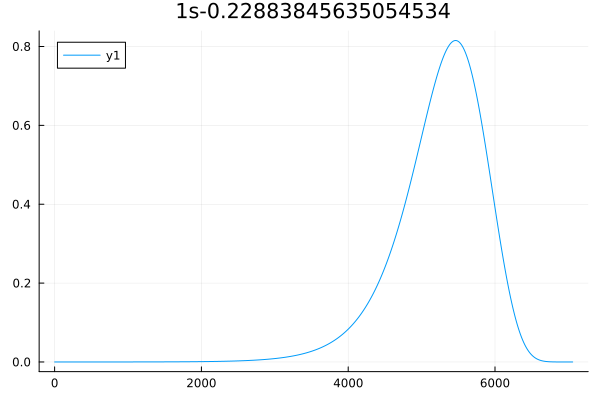

i_orbi.E -0.22878843786004163
--------------------------------
E_total -2.0529333013475153
*****************************************
1s


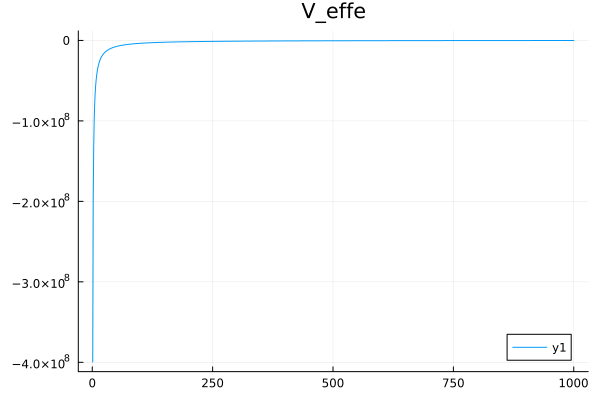

energy_interval (-0.26310670353904786, -0.14871248460902708)
E_intervals [(-0.22943883977369056, -0.2290562504127206)]


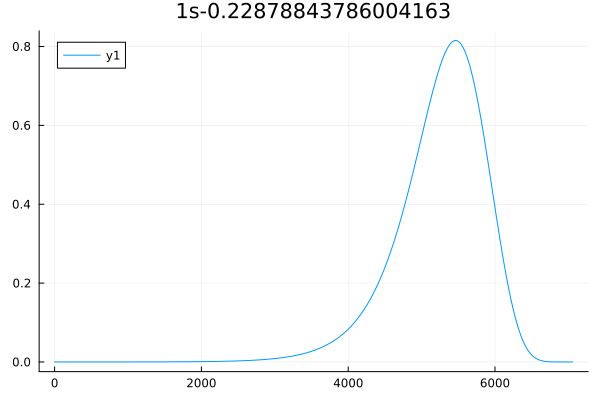

i_orbi.E -0.22874356240860633
--------------------------------
E_total -2.0529240320411057
*****************************************
1s


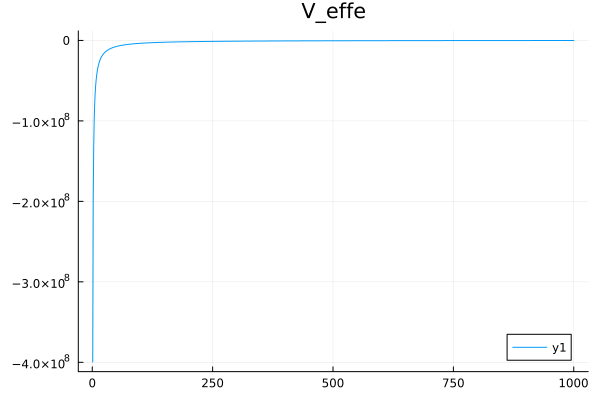

energy_interval (-0.26305509676989725, -0.1486833155655941)
E_intervals [(-0.22939383674990166, -0.22901132243149264)]


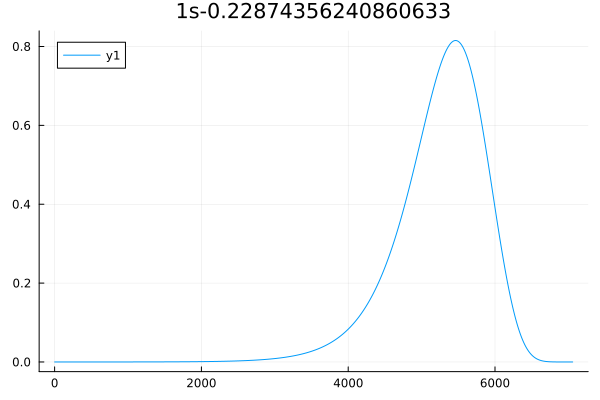

i_orbi.E -0.22870329971933476
--------------------------------
E_total -2.0529157219592755
*****************************************
1s


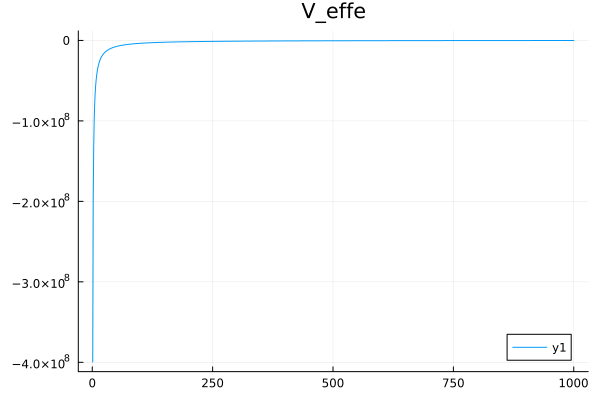

energy_interval (-0.263008794677235, -0.1486571448175676)
E_intervals [(-0.22935345960148001, -0.22897101261198283)]


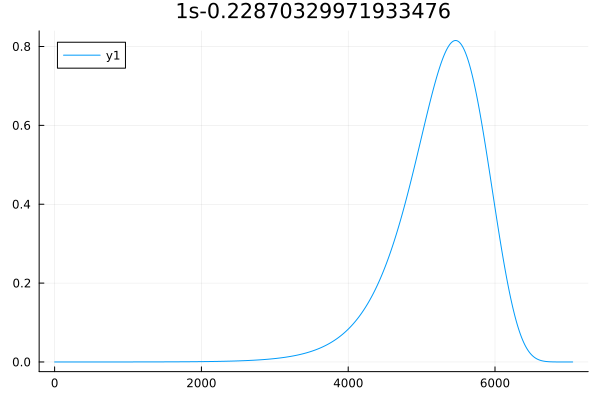

i_orbi.E -0.22866717442341464
--------------------------------
E_total -2.052908271092004
*****************************************
1s


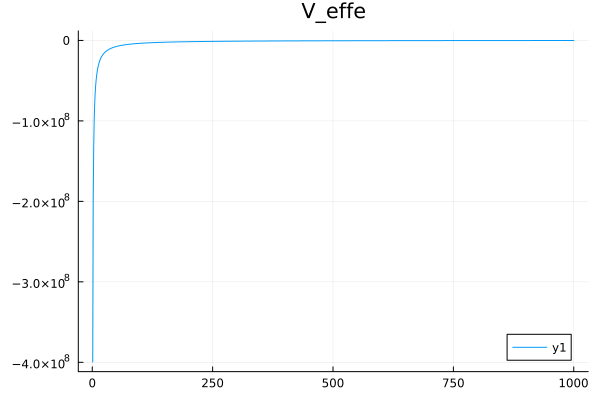

energy_interval (-0.2629672505869268, -0.14863366337521952)
E_intervals [(-0.22931723160823037, -0.228934845028927)]


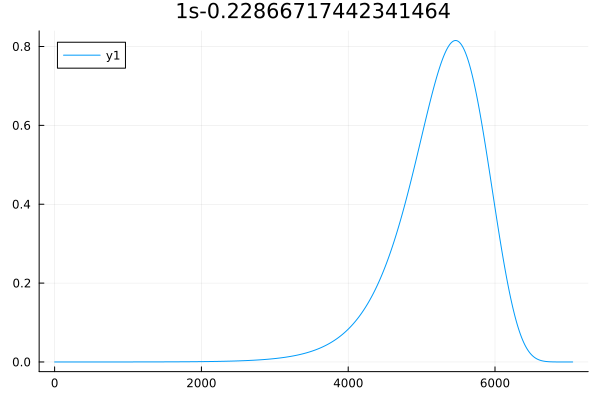

i_orbi.E -0.22863476033369876
--------------------------------
E_total -2.0529015899919614
*****************************************
1s


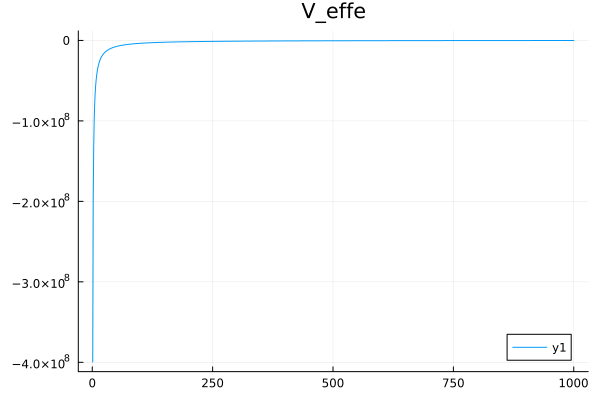

energy_interval (-0.26292997438375354, -0.1486125942169042)
E_intervals [(-0.22928472537143668, -0.22890239299629672)]


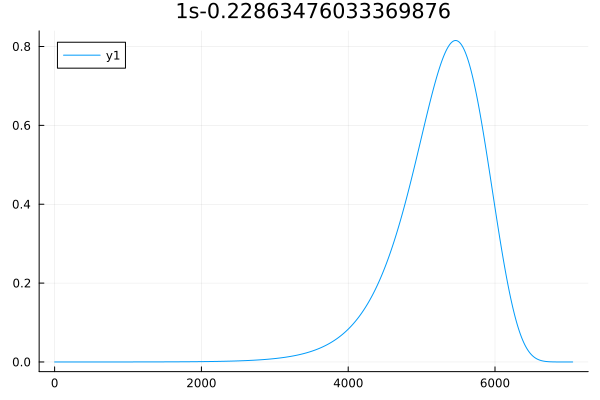

i_orbi.E -0.22860567532331622
--------------------------------
E_total -2.052895598633825
*****************************************
1s


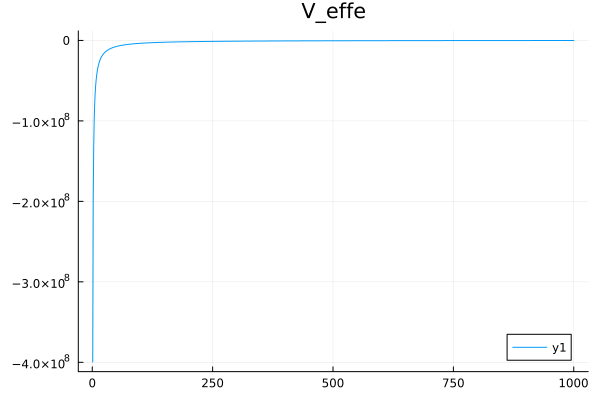

energy_interval (-0.2628965266218136, -0.14859368896015554)
E_intervals [(-0.22925555767791425, -0.2288732739399154)]


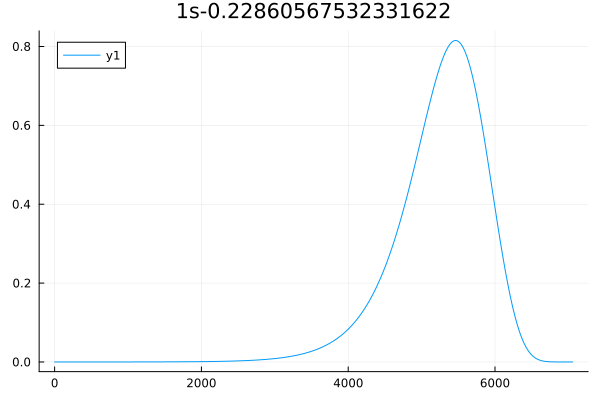

i_orbi.E -0.2285795767434673
--------------------------------
E_total -2.0528902254012533
*****************************************
1s


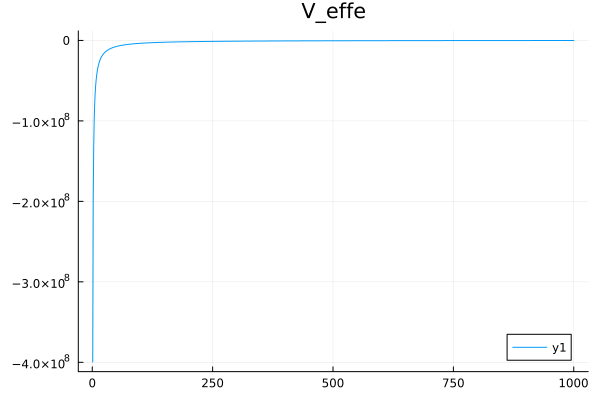

energy_interval (-0.2628665132549874, -0.14857672488325374)
E_intervals [(-0.22922938490477815, -0.2288471448098894)]


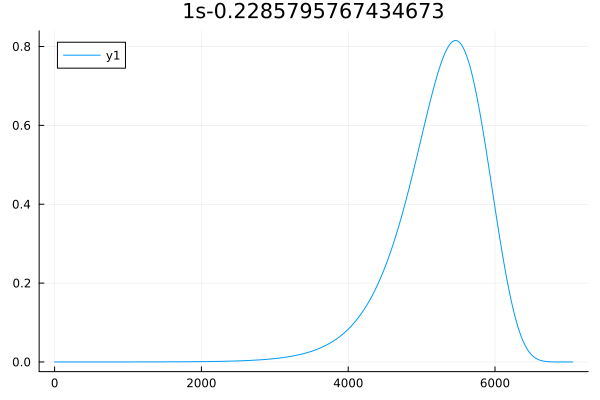

i_orbi.E -0.2285561573226315
--------------------------------
E_total -2.05288540618611
*****************************************
1s


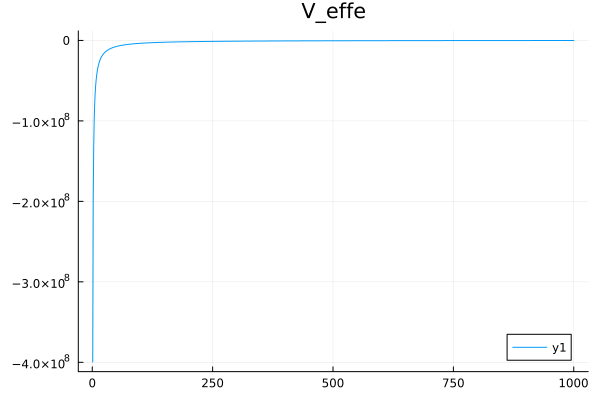

energy_interval (-0.2628395809210262, -0.1485615022597105)
E_intervals [(-0.2292058989069935, -0.22882369797501584)]


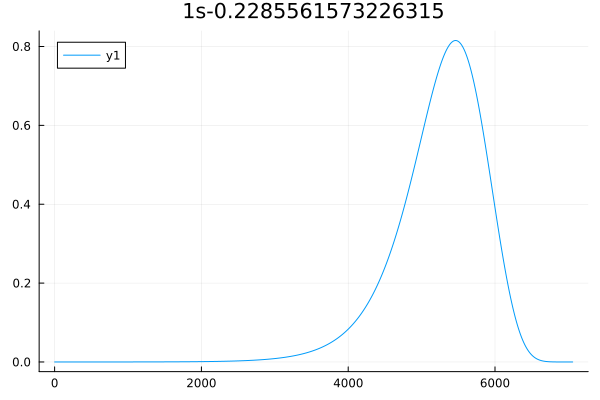

i_orbi.E -0.2285351414961617
--------------------------------
E_total -2.052881083588736
*****************************************
1s


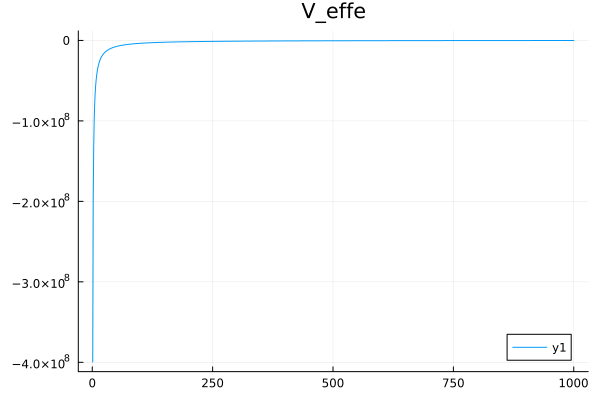

energy_interval (-0.26281541272058595, -0.1485478419725051)
E_intervals [(-0.2291848233365354, -0.22880265754808027)]


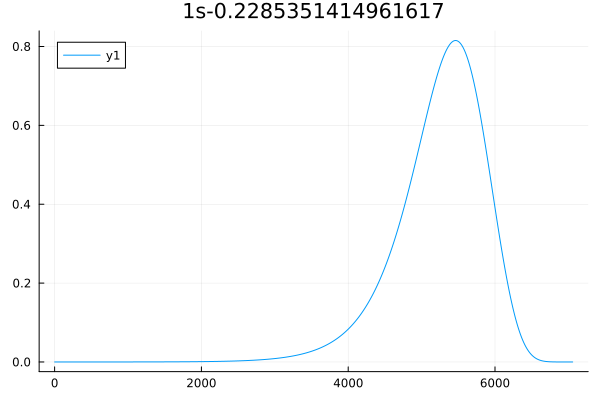

i_orbi.E -0.22851628211933003
--------------------------------
E_total -2.0528772062042426
*****************************************
1s


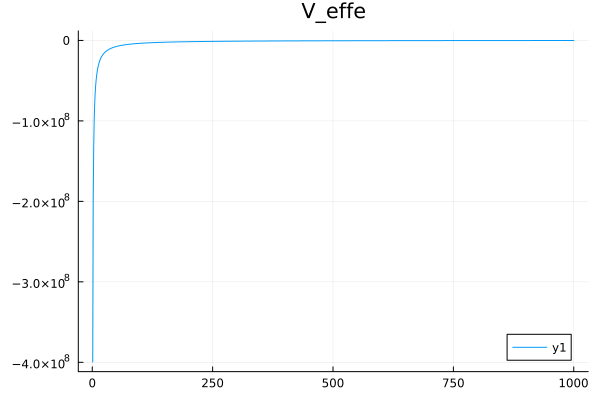

energy_interval (-0.26279372443722954, -0.1485355833775645)
E_intervals [(-0.22916591034609066, -0.228783776095055)]


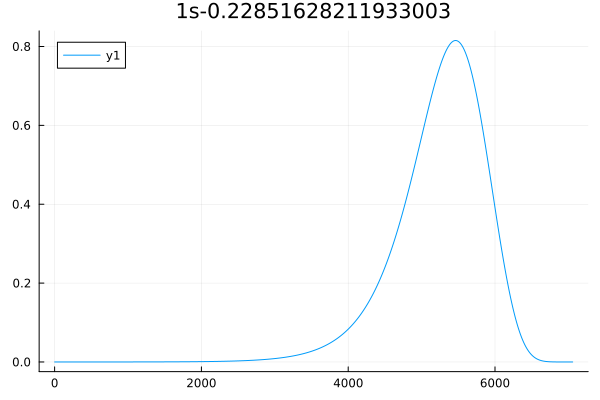

i_orbi.E -0.22849935752433886
--------------------------------
E_total -2.0528737279884495
*****************************************
1s


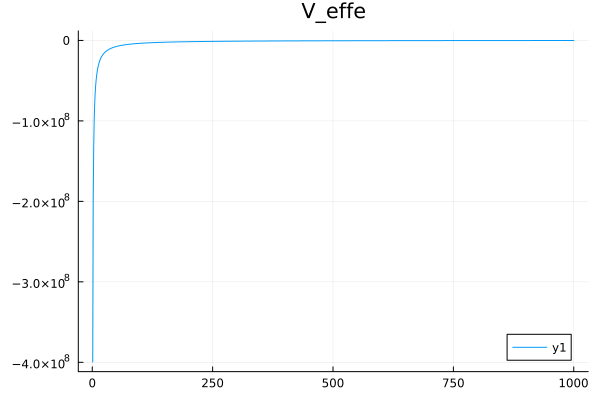

energy_interval (-0.2627742611529897, -0.14852458239082028)
E_intervals [(-0.2291489376377024, -0.22876683168866502)]


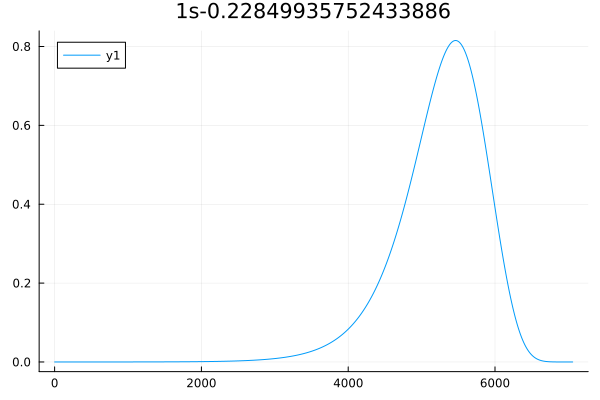

i_orbi.E -0.22848416888360198
--------------------------------
E_total -2.052870607690887
*****************************************
1s


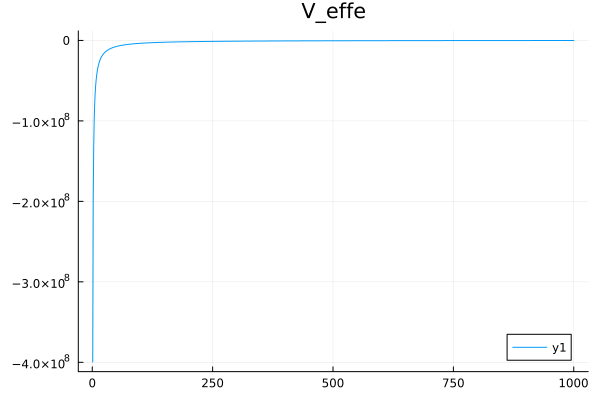

energy_interval (-0.2627567942161423, -0.14851470977434128)
E_intervals [(-0.22913370581855536, -0.22875162526858278)]


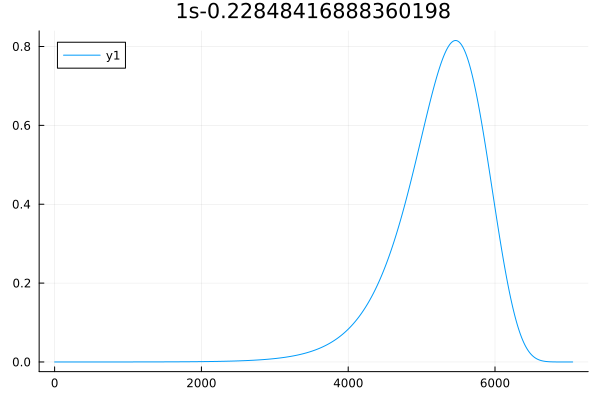

i_orbi.E -0.2284705378481984
--------------------------------
E_total -2.0528678083503986
*****************************************
1s


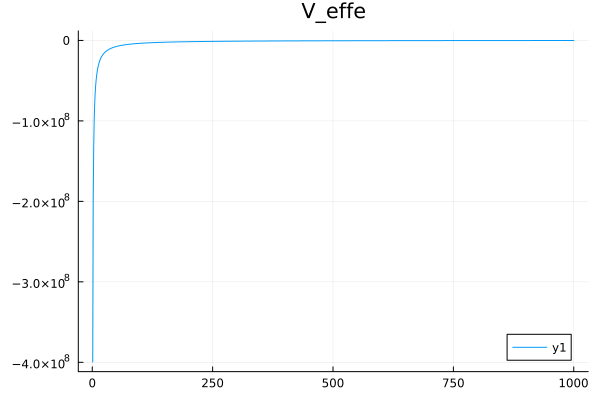

energy_interval (-0.26274111852542814, -0.14850584960132895)
E_intervals [(-0.2291200360327167, -0.22873797827711767)]


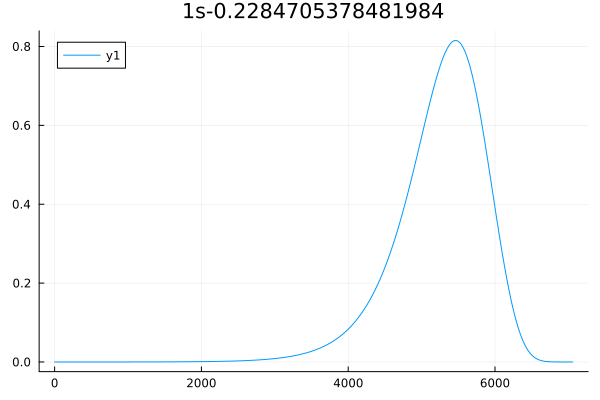

i_orbi.E -0.2284583044316574
--------------------------------
E_total -2.0528652968445553
*****************************************
1s


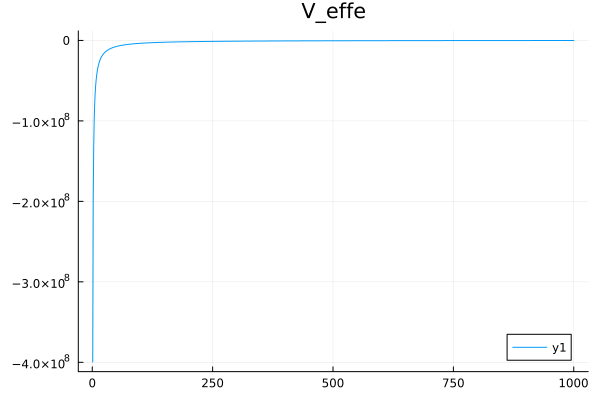

energy_interval (-0.262727050096406, -0.14849789788057732)
E_intervals [(-0.22910776783890457, -0.2287257305405239)]


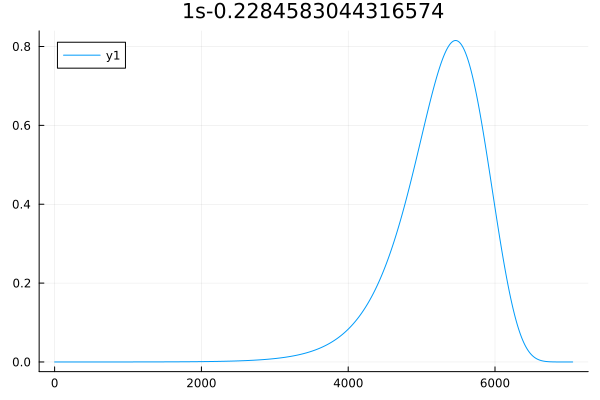

i_orbi.E -0.22844732511341379
--------------------------------
E_total -2.052863043486536
*****************************************
1s


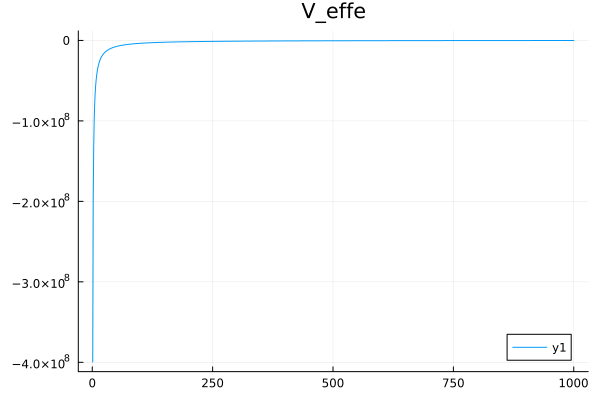

energy_interval (-0.2627144238804259, -0.14849076132371897)
E_intervals [(-0.22909675730855228, -0.22871473837023554)]


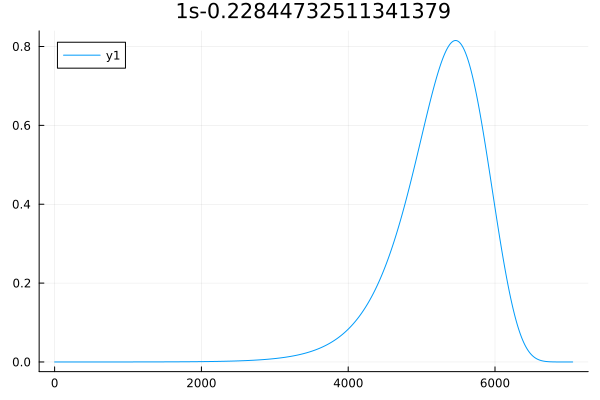

i_orbi.E -0.22843747113953342
--------------------------------
E_total -2.052861021666319
*****************************************
1s


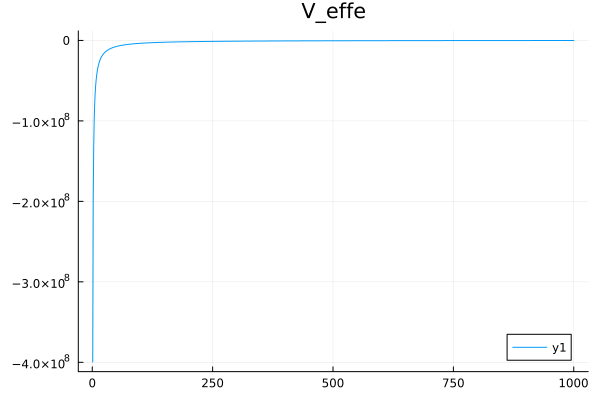

energy_interval (-0.2627030918104634, -0.14848435624069672)
E_intervals [(-0.22908687532170266, -0.2287048728616031)]


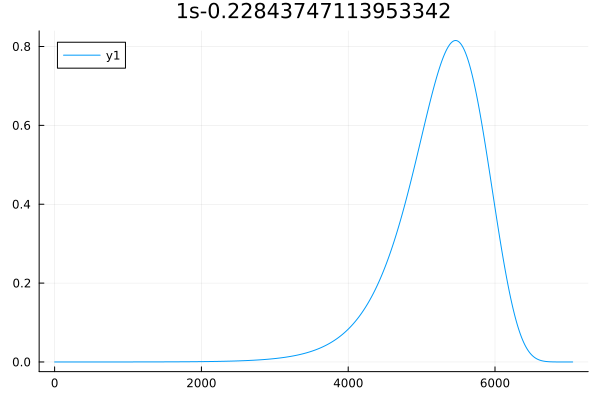

i_orbi.E -0.2284286269991655
--------------------------------
E_total -2.052859207528835
*****************************************
1s


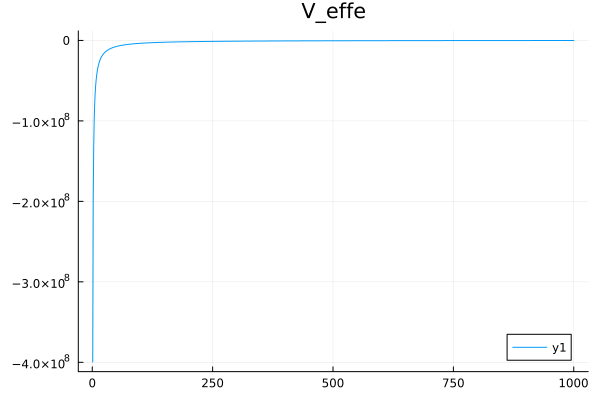

energy_interval (-0.2626929210490403, -0.14847860754945758)
E_intervals [(-0.22907800603912967, -0.2286960183685625)]


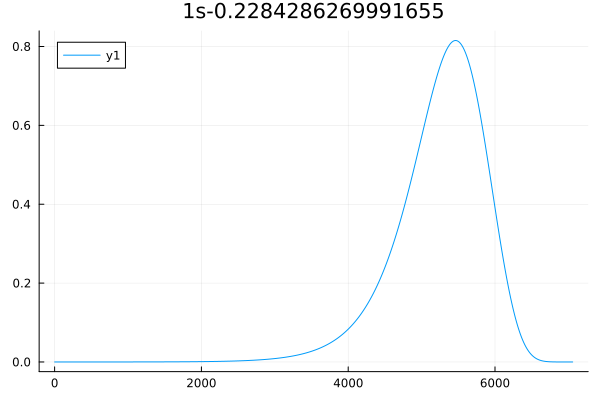

i_orbi.E -0.22842068905907134
--------------------------------
E_total -2.052857579686837
*****************************************
1s


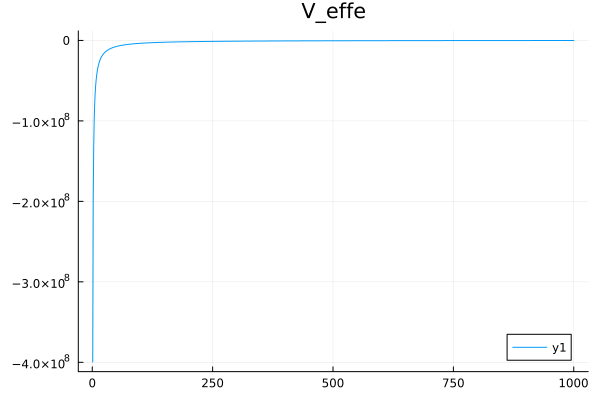

energy_interval (-0.26268379241793205, -0.1484734478883964)
E_intervals [(-0.2290700455329851, -0.22868807113656525)]


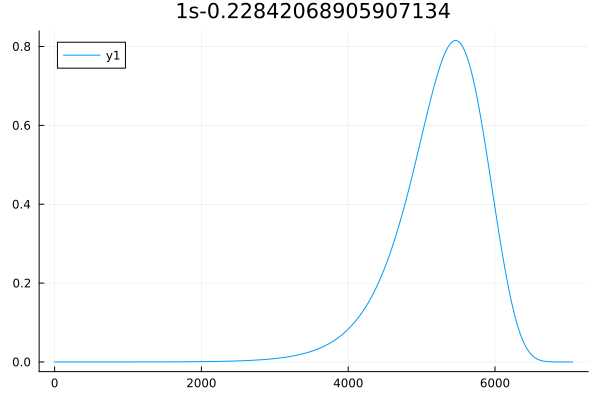

i_orbi.E -0.22841356433936594
--------------------------------
E_total -2.0528561189638976
*****************************************
1s


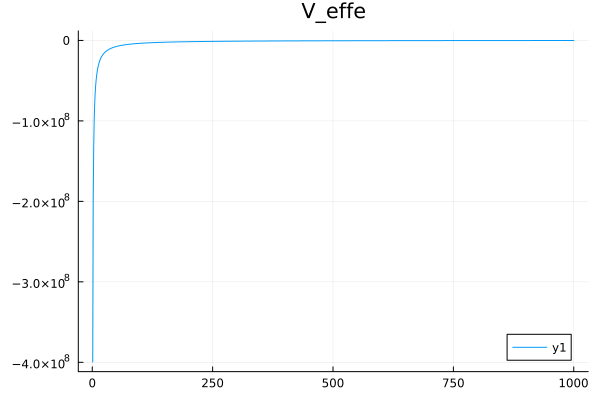

energy_interval (-0.2626755989902708, -0.14846881682058788)
E_intervals [(-0.22906290055905978, -0.22868093807688694)]


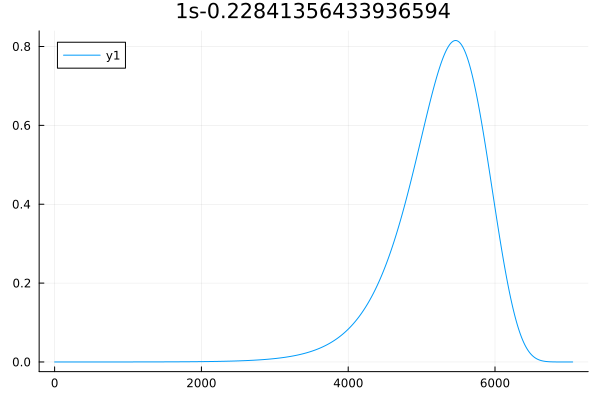

i_orbi.E -0.2284071694158994
--------------------------------
E_total -2.052854808164303
*****************************************
1s


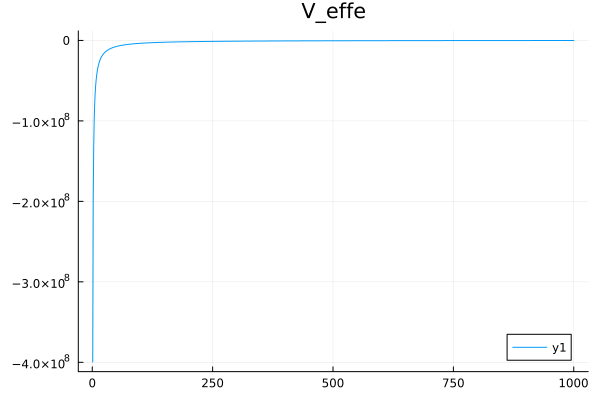

energy_interval (-0.2626682448282843, -0.1484646601203346)
E_intervals [(-0.22905648745604495, -0.22867453566772405)]


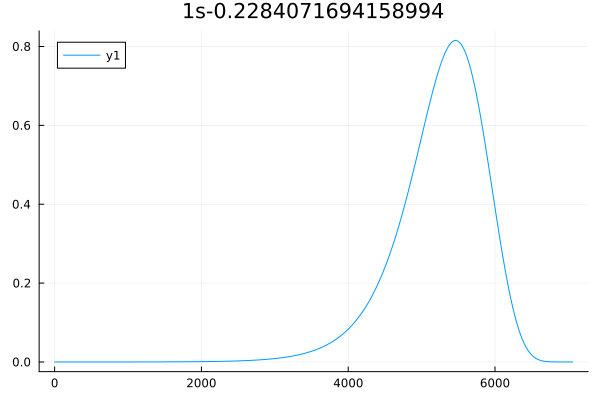

i_orbi.E -0.22840142943622127
--------------------------------
E_total -2.05285363186764
*****************************************
1s


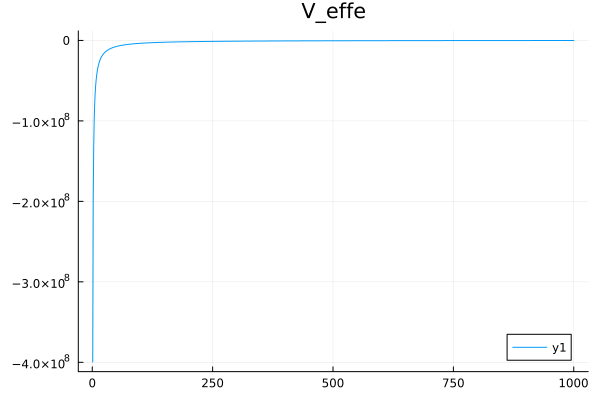

energy_interval (-0.26266164385165447, -0.14846092913354383)
E_intervals [(-0.22905073115869884, -0.22866878896900616)]


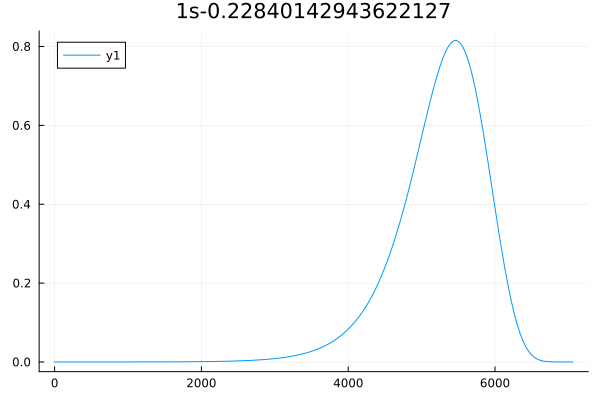

i_orbi.E -0.22839627723693953
--------------------------------
E_total -2.052852576244276
*****************************************
1s


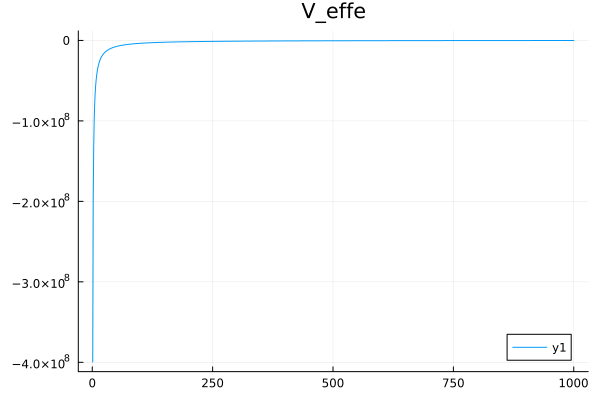

energy_interval (-0.26265571882248046, -0.1484575802040107)
E_intervals [(-0.2290455643126967, -0.2286636307387219)]


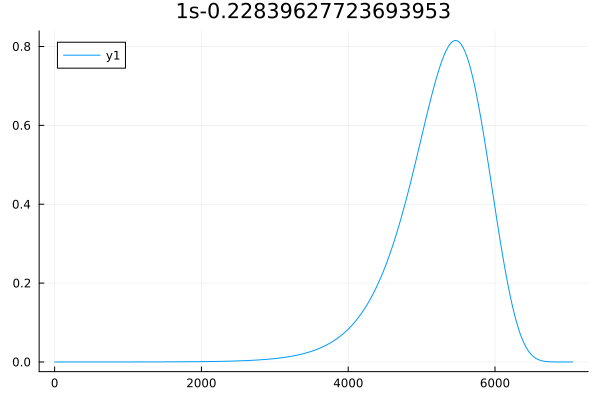

i_orbi.E -0.22839165255249394
--------------------------------
E_total -2.052851628890764
*****************************************
1s


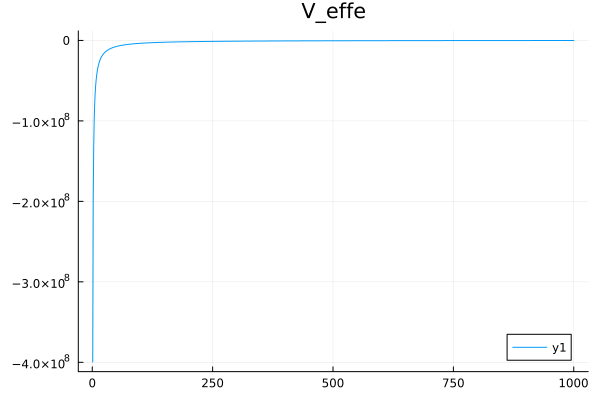

energy_interval (-0.262650400435368, -0.14845457415912106)
E_intervals [(-0.22904092648115487, -0.22865900064076608)]


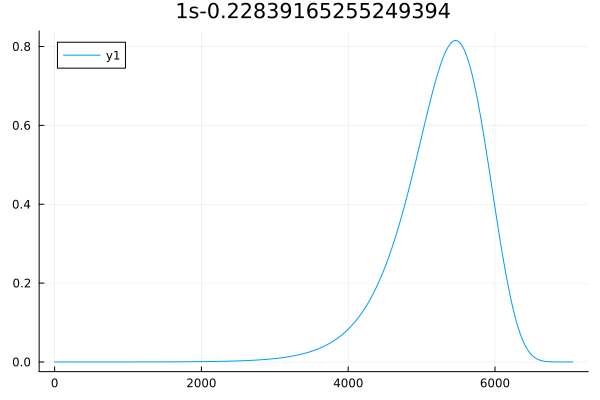

i_orbi.E -0.2283875013052717
--------------------------------
E_total -2.052850778681728
*****************************************
1s


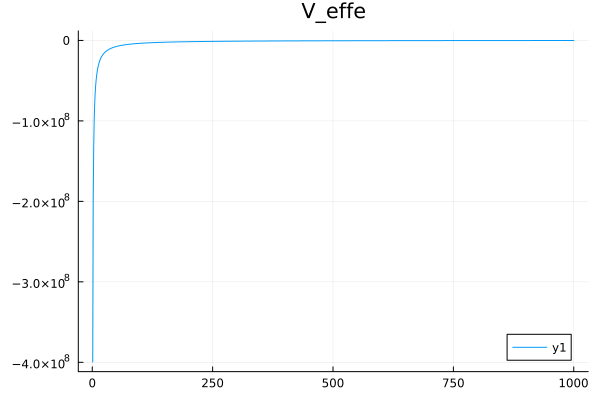

energy_interval (-0.26264562650106243, -0.14845187584842662)
E_intervals 

In [ ]:
#Energy minimization loop 
while abs(E_total - E_total_before) > 10.0e-8
    E_eigen=0.0;
    #Loop over every orbital to solve independent particle Schrodinger equation.
    for i_orbi in basis.orbitals
        println(i_orbi.name)
        #angular potential for l orbital
        V_angu= Potentials.angular_potential(i_orbi.l, grid_stru.grid);
        #Assemble effective potential.
        V_effe= V_colu .+ V_angu .+ V_hartree .+ V_xcp;# .+ V_x .+ V_c;
        Plots.display(plot(grid_stru.grid_i[1:1000], V_effe[1:1000], title= "V_effe"))   
        V_effe_max= maximum(V_effe)
        V_effe_min= minimum(V_effe)
        energy_interval= EigenvalueFinders.guess_energy_interval(i_orbi.E, V_effe_max, V_effe_min);
        println("energy_interval ", energy_interval)
        E_grid= Grids.UniformGrid(energy_interval[1], energy_interval[2], 300); #List with the energy grid points.

        E_intervals= EigenvalueFinders.find_eigenvalue_intervals(E_grid.grid, V_effe, grid_stru,
                    initial_condition_function_x_min,
                    initial_condition_function_x_max;
                    l=i_orbi.l);
        println("E_intervals ", E_intervals)
        u_temp, ei_temp= EigenvalueFinders.illinois_eigenvalue_finder(E_intervals[1], V_effe, 
        grid_stru,initial_condition_function_x_min,
        initial_condition_function_x_max,i_orbi.l);
        Plots.display(plot(grid_stru.grid_i, u_temp, title= string(i_orbi.name,i_orbi.E)))        
        #Update eigenvalue and eigenfunction in the basis set data structure.
        i_orbi.E=ei_temp;
        i_orbi.u=u_temp;
        E_eigen+= i_orbi.occu*ei_temp;
        println("i_orbi.E ",i_orbi.E)
        println("--------------------------------")

    end
    #Update E_total_before from the E_total from the previous step.
    E_total_before= float(E_total);
    #Calculate density with new basis set.
    density_out= Density.calculate_density(basis);
    #Smooth the density with linear mixing (combination) of the previous and current densities.
    density_in= Density.linear_mixing(density_in, density_out, alpha=0.10);
    #Solve Poisson equation to find the new Hartree potential.
    V_hartree= OneDPoissonEquationSolver.solver_uniform_integer_grid(Z, density_in, grid_stru);
    #Calculate new exchange and correlation potentials.
    xc_all = evaluate(xc, rho=density_in);
    #V_x, E_xp, V_c, E_cp= ExchangeCorrelation.potentials(density_in);
    #Add exchange and correlation potentials.
    V_xcp= vec(xc_all.vrho);#V_x .+ V_c;
    E_xp= vec(xc_all.zk);
    #Integrals to calculate energy components.

    V_xc= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, V_xcp)

    E_hartree= 0.5*4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, V_hartree);

    E_x= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, E_xp);

    #E_c= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, E_cp);

    #Calculate total energy.
    #E_total= E_eigen - E_hartree + E_x + E_c - V_xc;
    E_total= E_eigen - E_hartree + E_x  - V_xc;
    println("E_total ", E_total)
    println("*****************************************")
end
println("E_hartree ", E_hartree)
println("E_x + E_c ", E_x )
println("E_total ", E_total)
for i_orbi in basis.orbitals
    println(i_orbi.name)
    println(i_orbi.E)
end

In [8]:
E_grid.grid

LoadError: UndefVarError: `E_grid` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [ ]:


xc = Functional(:lda_x);
xc_all = evaluate(xc, rho=density_in);

In [ ]:
xc_all.vrho

xc_all.zk

LoadError: UndefVarError: `xc_all` not defined

In [17]:
result['zk']

LoadError: ParseError:
[90m# Error @ [0;0m]8;;file:///home/arturo_hernandez/Desktop/physics_coding_projects/julia/SchrodingerEquationSolver/examples/In[17]#1:9\[90mIn[17]:1:9[0;0m]8;;\
result['[48;2;120;70;70mzk[0;0m']
[90m#       └┘ ── [0;0m[91mcharacter literal contains multiple characters[0;0m

In [ ]:
#Energy minimization loop 
while abs(E_total - E_total_before) > 10.0e-8
    E_eigen=0.0;
    #Loop over every orbital to solve independent particle Schrodinger equation.
    for i_orbi in basis.orbitals
        #println(i_orbi.name)
        #angular potential for l orbital
        V_angu= Potentials.angular_potential(i_orbi.l, grid_stru.grid);
        #Assemble effective potential.
        V_effe= V_colu .+ V_angu .+ V_hartree .+ V_x .+ V_c;
        Plots.display(plot(grid_stru.grid_i, V_effe, title= "V_effe"))
        V_effe_max= maximum(V_effe)
        V_effe_min= minimum(V_effe)
        energy_interval= EigenvalueFinders.guess_energy_interval(i_orbi.E, V_effe_max, V_effe_min);
        E_grid= Grids.uniform_grid(energy_interval[1], energy_interval[2], 200); #List with the energy grid points.

        E_intervals= EigenvalueFinders.find_eigenvalue_intervals(E_grid, V_effe, grid_stru,
                    InitialConditions.atom_exponential_grid,
                        OneDSchrodingerEquationSolver.solver_exponential_grid, numb_inter=1);
        #print("here ")
        u_temp, ei_temp= EigenvalueFinders.illinois_eigenvalue_finder(E_intervals[1], V_effe, 
        grid_stru,InitialConditions.atom_exponential_grid, 
        OneDSchrodingerEquationSolver.solver_exponential_grid ,
        l=i_orbi.l);

        #Update eigenvalue and eigenfunction in the basis set data structure.
        i_orbi.E=ei_temp;
        i_orbi.u=u_temp;
        E_eigen+= i_orbi.occu*ei_temp;
        println(i_orbi.E)
        println("--------------------------------")

    end
    #Update E_total_before from the E_total from the previous step.
    E_total_before= float(E_total);
    #Calculate density with new basis set.
    density_out= Density.calculate_density(basis);
    #Smooth the density with linear mixing (combination) of the previous and current densities.
    density_in= Density.linear_mixing(density_in, density_out, alpha=0.10);
    #Solve Poisson equation to find the new Hartree potential.
    V_hartree= OneDPoissonEquationSolver.solver_exponential_grid(Z, density_in, grid_stru);
    #Calculate new exchange and correlation potentials.
    V_x, E_xp, V_c, E_cp= ExchangeCorrelation.potentials(density_in);
    #Add exchange and correlation potentials.
    V_xcp= V_x .+ V_c;
    #Integrals to calculate energy components.

    V_xc= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, V_xcp)

    E_hartree= 0.5*4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, V_hartree);

    E_x= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, E_xp);

    E_c= 4.0*pi*MathUtils.energy_integral_exponential_grid(grid_stru, density_in, E_cp);

    #Calculate total energy.
    E_total= E_eigen - E_hartree + E_x + E_c - V_xc;
    #println(E_total)
    #println("*****************************************")
end
println("E_hartree ", E_hartree)
println("E_x + E_c ", (E_x + E_c))
println("E_total ", E_total)
for i_orbi in basis.orbitals
    println(i_orbi.name)
    println(i_orbi.E)
end

E_hartree 8632.061100296987
E_x + E_c -381.91597334019093
E_total -21861.346869049703
1s
-3204.7577954682447
2s
-546.579772132307
2p
-527.5348078005222
3s
-133.37111165297298
3p
-124.17482066528329
4s
-31.232850906663906
3d
-106.94695043941988
4p
-27.11103205115545
5s
-5.89177045632627
4d
-19.452042001345298
5p
-4.410789674571185
6s
-0.6286084094262772
4f
-8.955370479704818
5d
-1.9134129941848175
6p
-0.2951682140037462


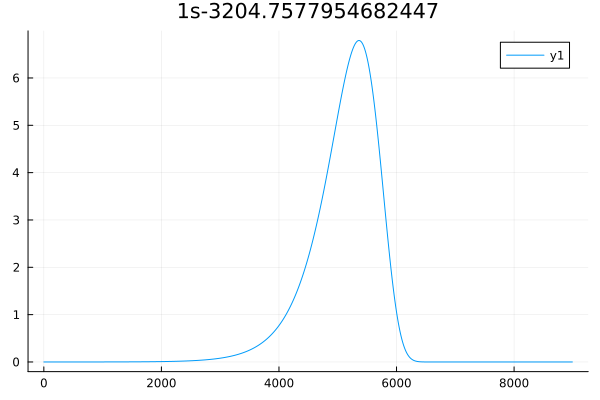

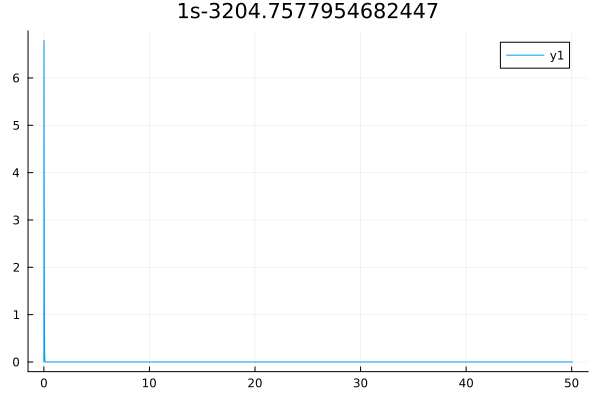

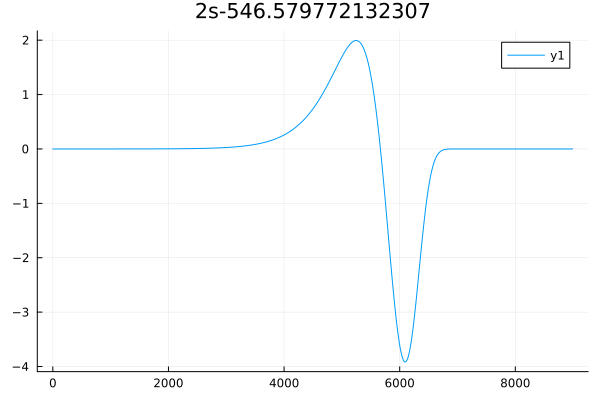

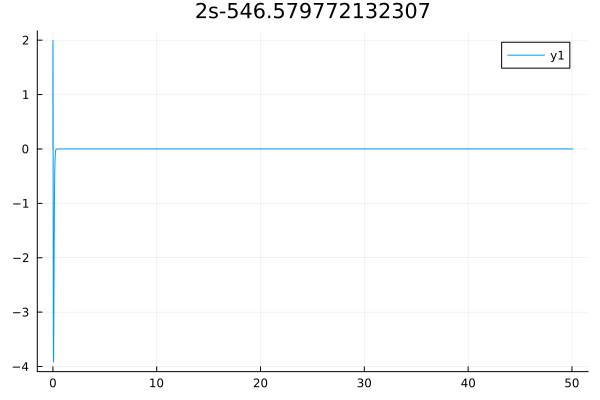

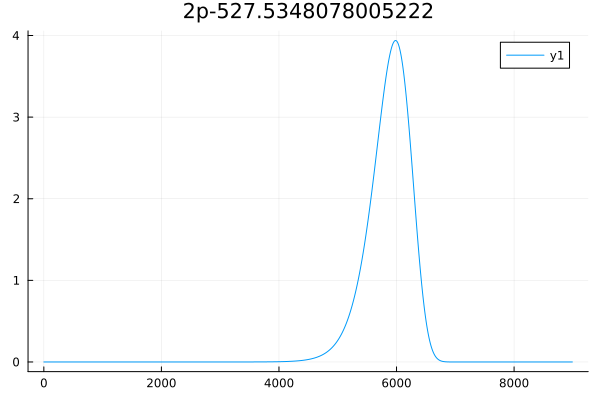

...

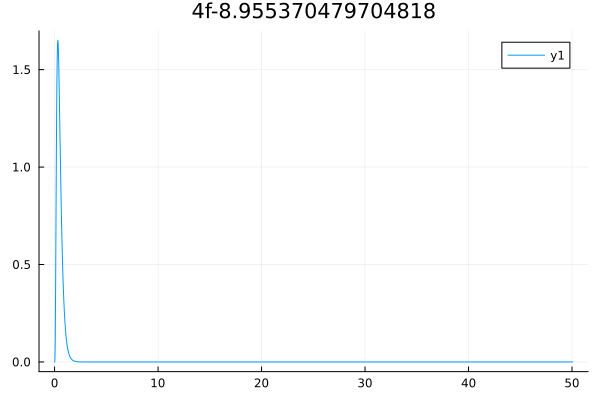

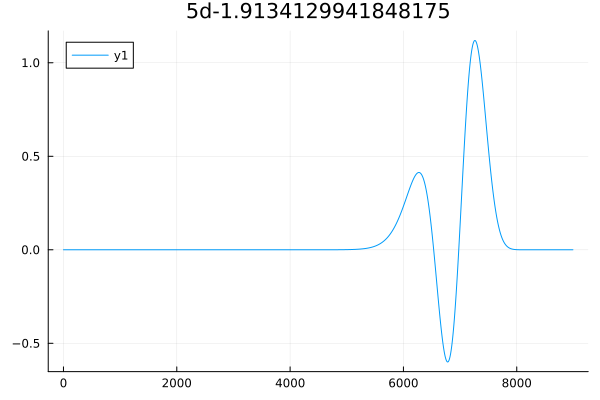

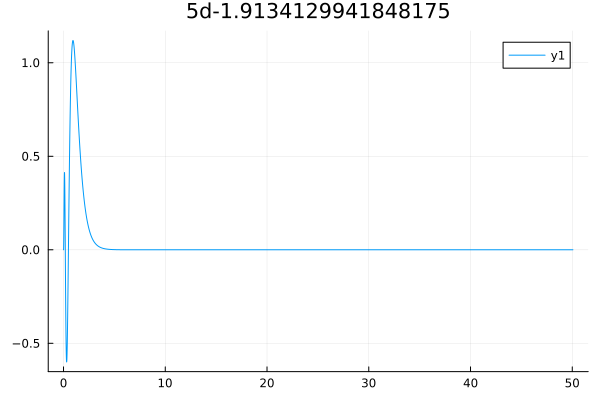

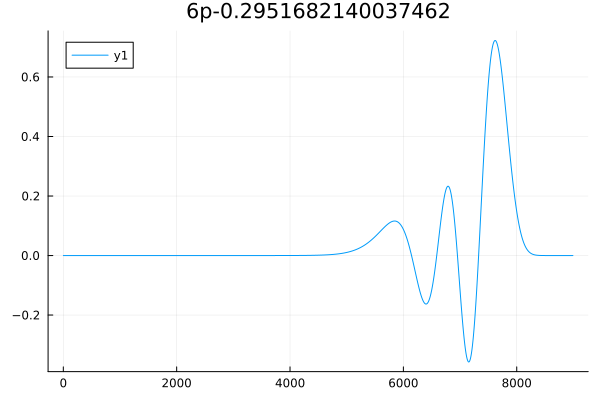

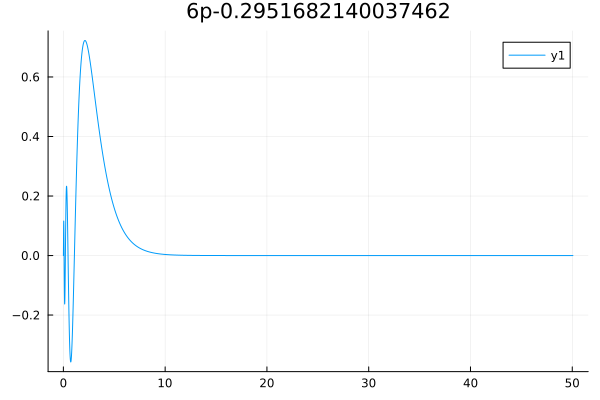

In [7]:
for i_orbi in basis.orbitals
    #println(i_orbi.name)
    #println(i_orbi.E)
    Plots.display(plot(grid_stru.grid_i, i_orbi.u, title= string(i_orbi.name,i_orbi.E)))
    Plots.display(plot(grid_stru.grid, i_orbi.u, title= string(i_orbi.name,i_orbi.E)))
end

#Define parameters and produce an exponential grid.

r_max::Float64=50.0;#Max radius of space grid.

Z::Int64=36;#Atomic number, also used as the charge of coulomb potential.



E_total -2750.1479408019813

18m 45.6s

using numb_inter=0


E_total -2750.147940802046

3m 18.0s

using numb_inter=1

************************************************************************************

#Define parameters and produce an exponential grid.

r_max::Float64=50.0;#Max radius of space grid.

Z::Int64=86;#Atomic number, also used as the charge of coulomb potential.


E_total -21861.34686904983

39m 47.1s

using numb_inter=0

E_total -21861.346869049754

7m 12.6s

using numb_inter=1
